# Credit Risk Intelligence
### End-to-End Machine Learning Pipeline for Credit Default Prediction

**Author:** Raghuvendra
**Date:** October 2026
**Tools:** Python | Scikit-learn | XGBoost | LightGBM | SHAP | Optuna | Gradio

---

This notebook builds a credit risk assessment system that predicts the probability
that a borrower defaults, converts it to a 300-850 score, explains it with SHAP,
monitors drift with PSI, and serves it through a Gradio dashboard.

| Component | Approach |
|-----------|----------|
| Exploratory Analysis | Distributions, default rates, correlations |
| Feature Engineering | Domain ratios, Information Value (IV) ranking |
| Modeling | Logistic Regression, Random Forest, XGBoost (Optuna), LightGBM |
| Decision Threshold | Cost-based (missed default costs 7.5x a rejected good applicant) |
| Explainability | SHAP (global + local) |
| Scorecard | Points-based score, KS and Gini |
| Monitoring | Population Stability Index (PSI) |
| Deployment | Gradio dashboard |

## Table of Contents

1. Setup and Configuration
2. Business Problem Definition
3. Data Acquisition
4. Exploratory Data Analysis
5. Feature Engineering
6. Data Preprocessing
7. Model Development
8. Model Evaluation and Comparison
9. Model Explainability (SHAP)
10. Credit Scorecard
11. Model Monitoring (PSI)
12. Interactive Risk Assessment Dashboard
13. Conclusion

---
## 1. Setup and Configuration

In [2]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    confusion_matrix, f1_score, accuracy_score, precision_score, recall_score,
    log_loss
)

import shap
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.figsize': (12, 6),
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'figure.dpi': 100,
})

COLORS = {
    'primary': '#2C3E50',
    'danger':  '#E74C3C',
    'info':    '#3498DB',
    'success': '#27AE60',
    'warning': '#F39C12',
    'purple':  '#9B59B6',
}

print("All libraries loaded successfully.")
print(f"NumPy {np.__version__}  |  Pandas {pd.__version__}")

All libraries loaded successfully.
NumPy 2.4.6  |  Pandas 3.0.3


---
## 2. Business Problem Definition

Lenders lose money on borrowers who default. The goal is to:
1. Predict the probability of default for each applicant
2. Convert it into an interpretable credit score
3. Explain each decision
4. Monitor the model over time

### Success Metrics

| Metric | Target | Rationale |
|--------|--------|-----------|
| ROC-AUC | > 0.80 | Strong class discrimination |
| Recall (Default) | > 0.70 | Catch most actual defaults |
| KS Statistic | > 0.40 | Good separation in the scorecard |
| Gini Coefficient | > 0.60 | Strong predictive power |

### Cost-Benefit Framework
- **False negative (missed default):** average loss of $15,000
- **False positive (rejected good applicant):** lost revenue of $2,000

For a calibrated model, the cost-minimising decision rule is to reject when
`P(default) > C_FP / (C_FP + C_FN) = 2000 / 17000 = 0.118`. This notebook uses that
threshold instead of the default 0.5, and does **not** resample the classes
(SMOTE would distort the probabilities that the scorecard and the threshold rely on).

---
## 3. Data Acquisition

A synthetic credit dataset is generated, with distributions modelled on credit-bureau
variables. It is reproducible and has no privacy or licensing issues.

> In production this data would come from credit bureaus, internal bank records, and
> alternative data sources.

In [3]:
def generate_credit_data(n_samples=50_000, random_state=42):
    """Generate synthetic credit data with a logistic default target."""
    rng = np.random.RandomState(random_state)

    # Demographics
    age = rng.normal(42, 13, n_samples).clip(18, 85).astype(int)
    education = rng.choice(
        ['High School', 'Associate', 'Bachelor', 'Master', 'Doctorate'],
        n_samples, p=[0.25, 0.15, 0.35, 0.18, 0.07],
    )
    marital_status = rng.choice(
        ['Single', 'Married', 'Divorced', 'Widowed'],
        n_samples, p=[0.30, 0.45, 0.18, 0.07],
    )
    dependents = rng.poisson(1.2, n_samples).clip(0, 6)

    # Employment and income
    employment_length = rng.exponential(6, n_samples).clip(0, 45).astype(int)
    edu_map = {'High School': 0.7, 'Associate': 0.85, 'Bachelor': 1.0,
               'Master': 1.3, 'Doctorate': 1.5}
    edu_mult = np.array([edu_map[e] for e in education])
    annual_income = (
        rng.lognormal(10.7, 0.6, n_samples) * edu_mult * (1 + 0.01 * employment_length)
    ).clip(12_000, 500_000)
    home_ownership = rng.choice(
        ['Rent', 'Own', 'Mortgage', 'Other'],
        n_samples, p=[0.30, 0.20, 0.45, 0.05],
    )

    # Credit history
    credit_limit = (annual_income * rng.uniform(0.2, 1.8, n_samples)).clip(500, 300_000)
    utilization_rate = rng.beta(2, 5, n_samples).clip(0, 1)
    revolving_balance = (credit_limit * utilization_rate).round(2)
    open_credit_lines = rng.poisson(6, n_samples).clip(1, 35)
    total_credit_lines = (open_credit_lines + rng.poisson(3, n_samples)).clip(open_credit_lines, 60)
    num_mortgages = np.where(
        np.isin(home_ownership, ['Own', 'Mortgage']),
        rng.choice([0, 1, 2, 3], n_samples, p=[0.15, 0.55, 0.25, 0.05]),
        0,
    )

    # Payment history
    late_30d = rng.poisson(0.5, n_samples).clip(0, 12)
    late_60d = np.minimum(rng.poisson(0.2, n_samples).clip(0, 8), late_30d)
    late_90d = np.minimum(rng.poisson(0.08, n_samples).clip(0, 5), late_60d)
    months_since_delinq = np.where(
        late_30d > 0,
        rng.exponential(15, n_samples).clip(1, 120).astype(float),
        np.nan,   # never delinquent
    )

    # Debt metrics
    monthly_debt = rng.lognormal(6.5, 0.9, n_samples).clip(50, 25_000)
    debt_to_income = ((monthly_debt * 12) / annual_income).clip(0, 5).round(4)
    inquiries_6m = rng.poisson(1.2, n_samples).clip(0, 20)
    months_since_inquiry = rng.exponential(8, n_samples).clip(0, 60).astype(int)

    # Target: logistic model on centred risk factors
    log_odds = (
        -3.5
        - 0.050 * (age - 42)
        - 0.00002 * (annual_income - 60_000)
        + 4.25 * (utilization_rate - 0.29)
        + 0.75 * late_30d
        + 1.00 * late_60d
        + 1.50 * late_90d
        + 1.50 * debt_to_income
        + 0.20 * inquiries_6m
        - 0.07 * employment_length
        + 0.13 * dependents
        + rng.normal(0, 0.2, n_samples)
    )
    prob = 1 / (1 + np.exp(-log_odds))
    default = (rng.random(n_samples) < prob).astype(int)

    # Inject missing values
    annual_income_m = annual_income.copy()
    annual_income_m[rng.random(n_samples) < 0.04] = np.nan
    emp_len_m = employment_length.astype(float).copy()
    emp_len_m[rng.random(n_samples) < 0.06] = np.nan

    return pd.DataFrame({
        'age': age,
        'education': education,
        'marital_status': marital_status,
        'dependents': dependents,
        'home_ownership': home_ownership,
        'annual_income': np.round(annual_income_m, 2),
        'employment_length': emp_len_m,
        'credit_limit': np.round(credit_limit, 2),
        'utilization_rate': np.round(utilization_rate, 4),
        'revolving_balance': revolving_balance,
        'open_credit_lines': open_credit_lines,
        'total_credit_lines': total_credit_lines,
        'num_mortgages': num_mortgages,
        'late_payments_30d': late_30d,
        'late_payments_60d': late_60d,
        'late_payments_90d': late_90d,
        'months_since_delinquency': months_since_delinq,
        'monthly_debt_payment': np.round(monthly_debt, 2),
        'debt_to_income': debt_to_income,
        'num_inquiries_6m': inquiries_6m,
        'months_since_last_inquiry': months_since_inquiry,
        'default': default,
    })


df = generate_credit_data(n_samples=50_000, random_state=RANDOM_STATE)
print(f"Dataset shape: {df.shape}")
print(f"Default rate:  {df['default'].mean():.2%}")
print(f"Memory usage:  {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
df.head()

Dataset shape: (50000, 22)
Default rate:  15.36%
Memory usage:  9.40 MB


,age,education,marital_status,dependents,home_ownership,annual_income,employment_length,credit_limit,utilization_rate,revolving_balance,...,num_mortgages,late_payments_30d,late_payments_60d,late_payments_90d,months_since_delinquency,monthly_debt_payment,debt_to_income,num_inquiries_6m,months_since_last_inquiry,default
0,48,High School,Divorced,1,Rent,24414.97,NaN,30397.54,0.0810,2461.90,...,0,0,0,0,NaN,548.12,0.2694,0,30,0
1,40,Associate,Married,2,Mortgage,42901.17,5.0,33869.87,0.2565,8686.41,...,0,1,1,0,5.015160,12529.52,3.5047,0,2,1
2,50,Master,Married,2,Mortgage,312467.48,1.0,206588.56,0.4220,87173.50,...,1,0,0,0,NaN,374.28,0.0144,0,9,0
3,61,Doctorate,Single,1,Own,34319.84,6.0,42754.03,0.1682,7189.34,...,2,1,1,0,10.604849,585.95,0.2049,0,2,1
4,38,High School,Divorced,0,Rent,13666.78,3.0,8298.79,0.6633,5504.99,...,0,1,0,0,1.396425,1027.62,0.9023,0,0,0


In [4]:
print("=" * 60)
print("DATA OVERVIEW")
print("=" * 60)
print(f"\nRows:    {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

print("\nColumn Types:")
print(df.dtypes.astype(str).value_counts())

missing = df.isnull().sum()
missing_df = pd.DataFrame({'Count': missing, 'Percentage': (missing / len(df) * 100).round(2)})
print("\nMissing Values:")
print(missing_df[missing_df['Count'] > 0])

print("\nNumerical Summary:")
df.describe().round(2)

DATA OVERVIEW

Rows:    50,000
Columns: 22

Column Types:
int64      11
float64     8
str         3
Name: count, dtype: int64

Missing Values:
                          Count  Percentage
annual_income              2048        4.10
employment_length          2945        5.89
months_since_delinquency  30295       60.59

Numerical Summary:


,age,dependents,annual_income,employment_length,credit_limit,utilization_rate,revolving_balance,open_credit_lines,total_credit_lines,num_mortgages,late_payments_30d,late_payments_60d,late_payments_90d,months_since_delinquency,monthly_debt_payment,debt_to_income,num_inquiries_6m,months_since_last_inquiry,default
count,50000.00,50000.00,47952.00,47055.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.0,50000.00,50000.00,19705.00,50000.00,50000.00,50000.0,50000.00,50000.00
mean,41.68,1.21,55221.20,5.48,54847.79,0.28,15713.92,6.01,9.01,0.78,0.5,0.07,0.01,15.00,986.91,0.32,1.2,7.52,0.15
std,12.59,1.10,39531.30,5.95,47774.37,0.16,18199.89,2.45,3.00,0.83,0.7,0.27,0.07,14.86,1118.54,0.44,1.1,7.95,0.36
min,18.00,0.00,12000.00,0.00,2400.90,0.00,33.70,1.00,1.00,0.00,0.0,0.00,0.00,1.00,50.00,0.00,0.0,0.00,0.00
25%,33.00,0.00,29013.19,1.00,22274.68,0.16,4553.26,4.00,7.00,0.00,0.0,0.00,0.00,4.37,359.96,0.08,0.0,2.00,0.00
50%,42.00,1.00,44743.38,4.00,40629.68,0.26,9772.54,6.00,9.00,1.00,0.0,0.00,0.00,10.40,656.68,0.18,1.0,5.00,0.00
75%,50.00,2.00,69347.49,8.00,71305.14,0.39,19953.49,8.00,11.00,1.00,1.0,0.00,0.00,20.72,1204.57,0.37,2.0,11.00,0.00
max,85.00,6.00,500000.00,45.00,300000.00,0.91,238066.61,18.00,25.00,3.00,5.0,2.00,1.00,120.00,25000.00,5.00,8.0,60.00,1.00


---
## 4. Exploratory Data Analysis

### 4.1 Target Variable

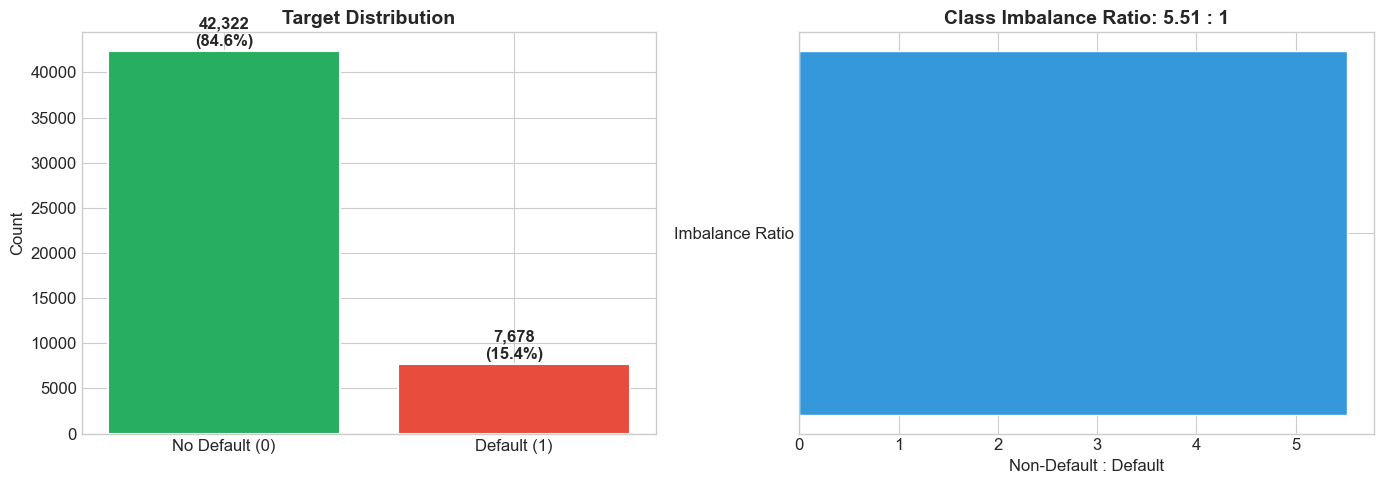

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

counts = df['default'].value_counts().sort_index()
bars = axes[0].bar(
    ['No Default (0)', 'Default (1)'], counts.values,
    color=[COLORS['success'], COLORS['danger']], edgecolor='white', linewidth=1.5,
)
for bar, c in zip(bars, counts.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2, bar.get_height() + 300,
        f'{c:,}\n({c / len(df) * 100:.1f}%)', ha='center', va='bottom', fontweight='bold',
    )
axes[0].set_title('Target Distribution', fontweight='bold')
axes[0].set_ylabel('Count')

ratio = counts[0] / counts[1]
axes[1].barh(['Imbalance Ratio'], [ratio], color=COLORS['info'], edgecolor='white')
axes[1].set_title(f'Class Imbalance Ratio: {ratio:.2f} : 1', fontweight='bold')
axes[1].set_xlabel('Non-Default : Default')

plt.tight_layout()
plt.show()

### 4.2 Numerical Feature Distributions

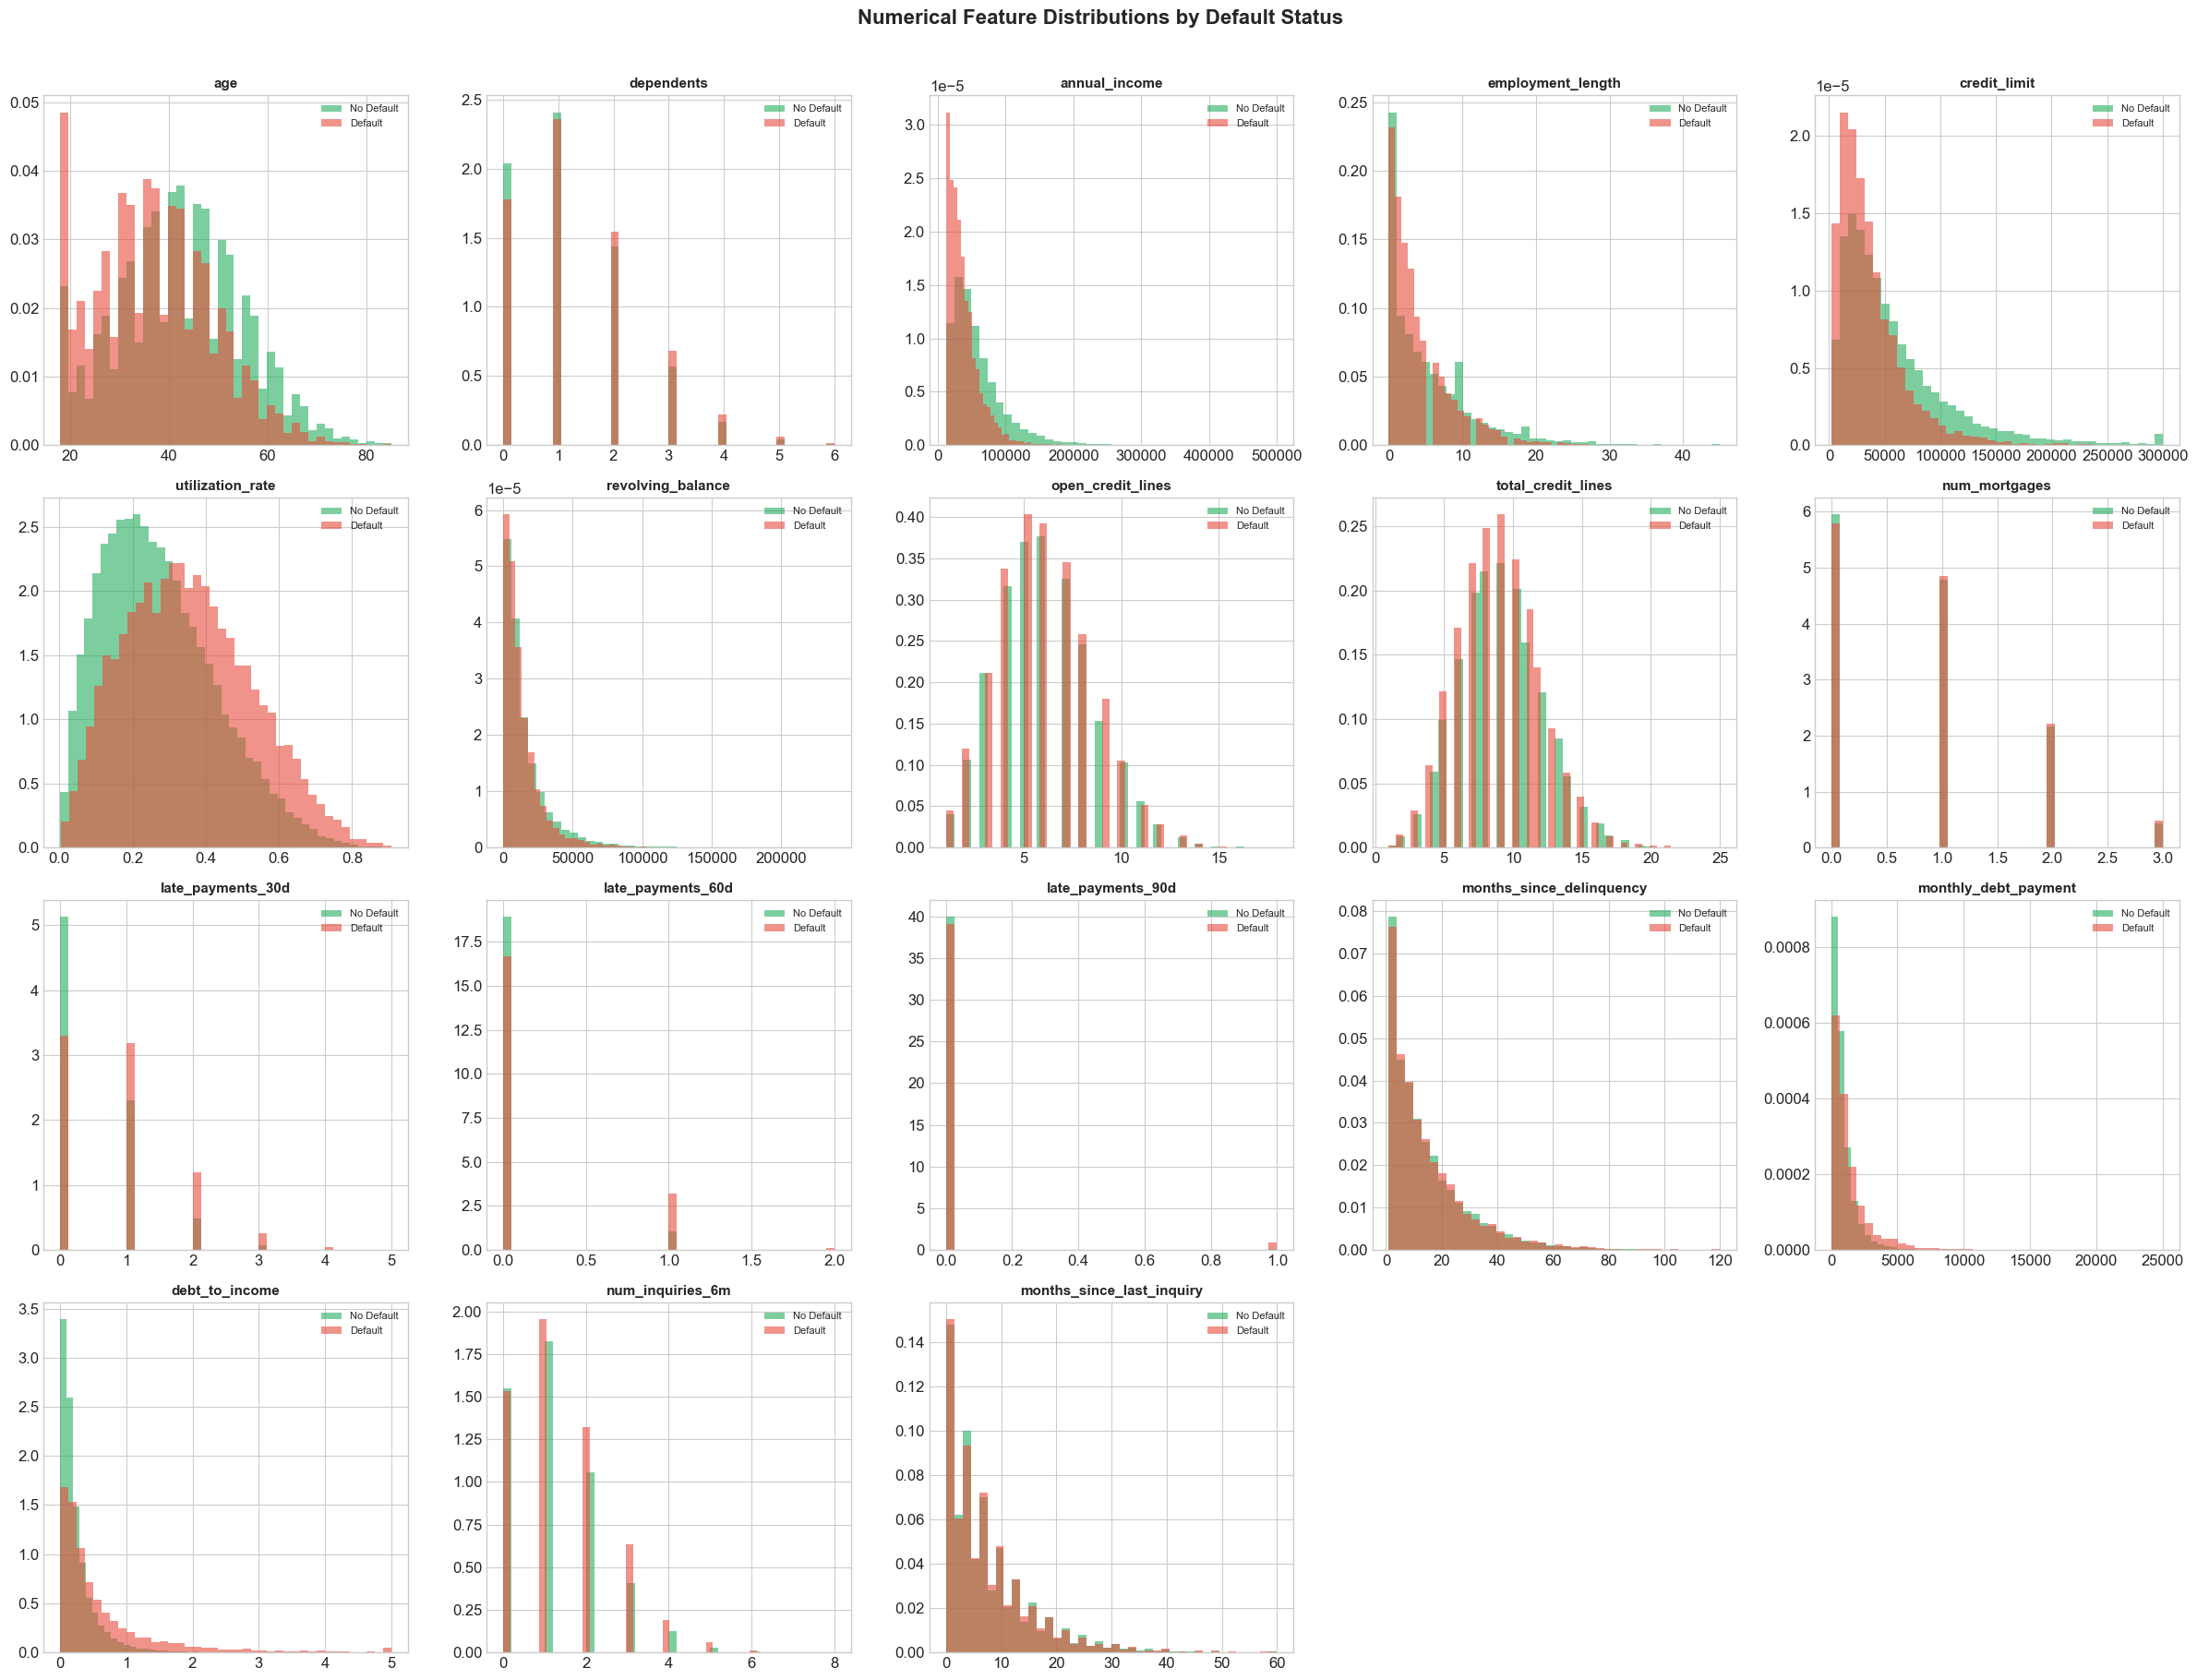

In [6]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.drop('default').tolist()

n_cols = 5
n_rows = int(np.ceil(len(numerical_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(24, 4.5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    ax = axes[i]
    for label, color, name in [(0, COLORS['success'], 'No Default'),
                               (1, COLORS['danger'], 'Default')]:
        subset = df.loc[df['default'] == label, col].dropna()
        ax.hist(subset, bins=40, alpha=0.6, color=color, label=name, density=True)
    ax.set_title(col, fontweight='bold', fontsize=11)
    ax.legend(fontsize=8)

for j in range(len(numerical_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Numerical Feature Distributions by Default Status',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 4.3 Categorical Feature Analysis

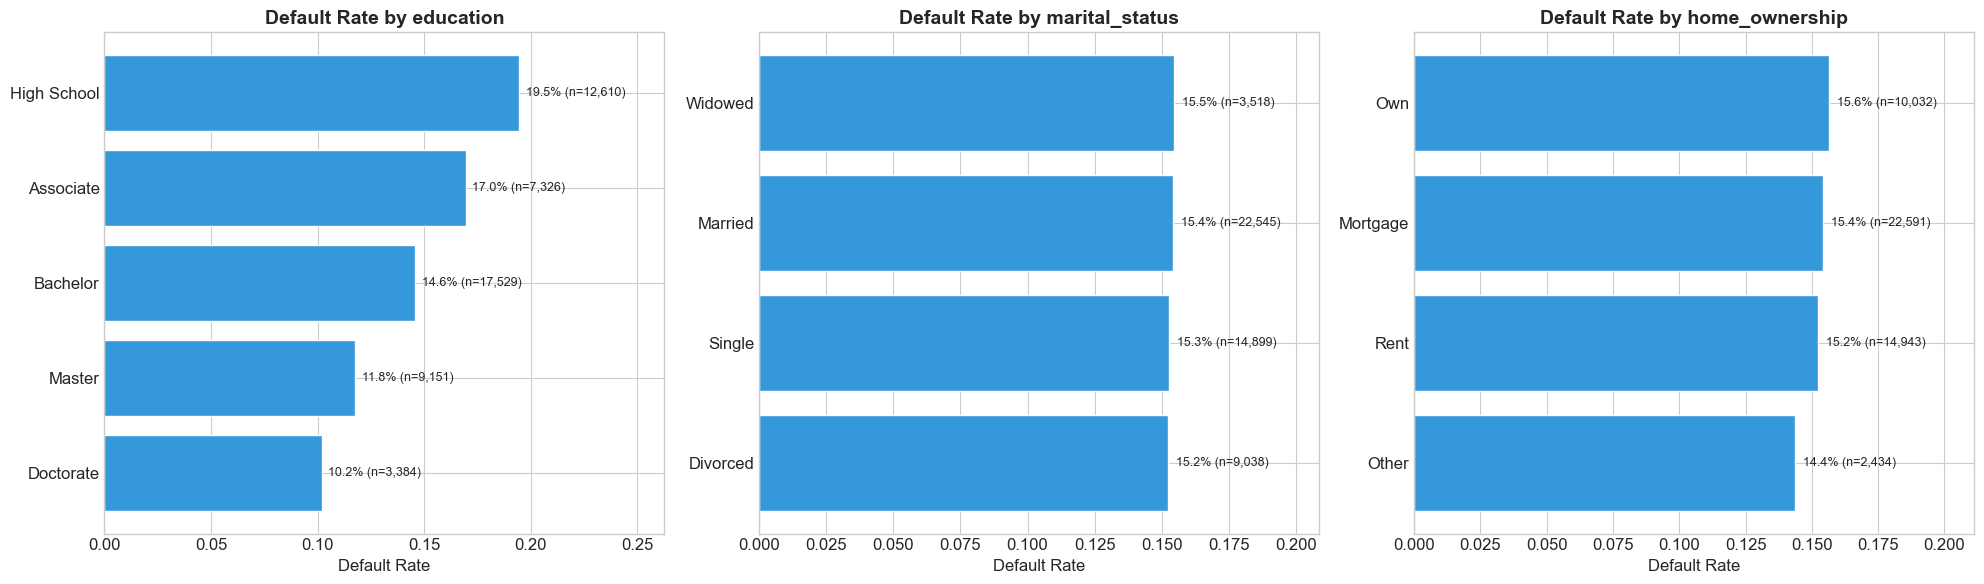

In [7]:
categorical_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()

fig, axes = plt.subplots(1, len(categorical_cols), figsize=(20, 6))

for i, col in enumerate(categorical_cols):
    stats = (
        df.groupby(col)['default']
        .agg(['mean', 'count'])
        .reset_index()
        .rename(columns={'mean': 'default_rate', 'count': 'n'})
        .sort_values('default_rate', ascending=True)
    )
    bars = axes[i].barh(stats[col], stats['default_rate'],
                        color=COLORS['info'], edgecolor='white')
    axes[i].set_title(f'Default Rate by {col}', fontweight='bold')
    axes[i].set_xlabel('Default Rate')
    axes[i].set_xlim(0, stats['default_rate'].max() * 1.35)
    for bar, rate, n in zip(bars, stats['default_rate'], stats['n']):
        axes[i].text(bar.get_width() + 0.003, bar.get_y() + bar.get_height() / 2,
                     f'{rate:.1%} (n={n:,})', va='center', fontsize=9)

plt.tight_layout()
plt.show()

### 4.4 Correlation Analysis

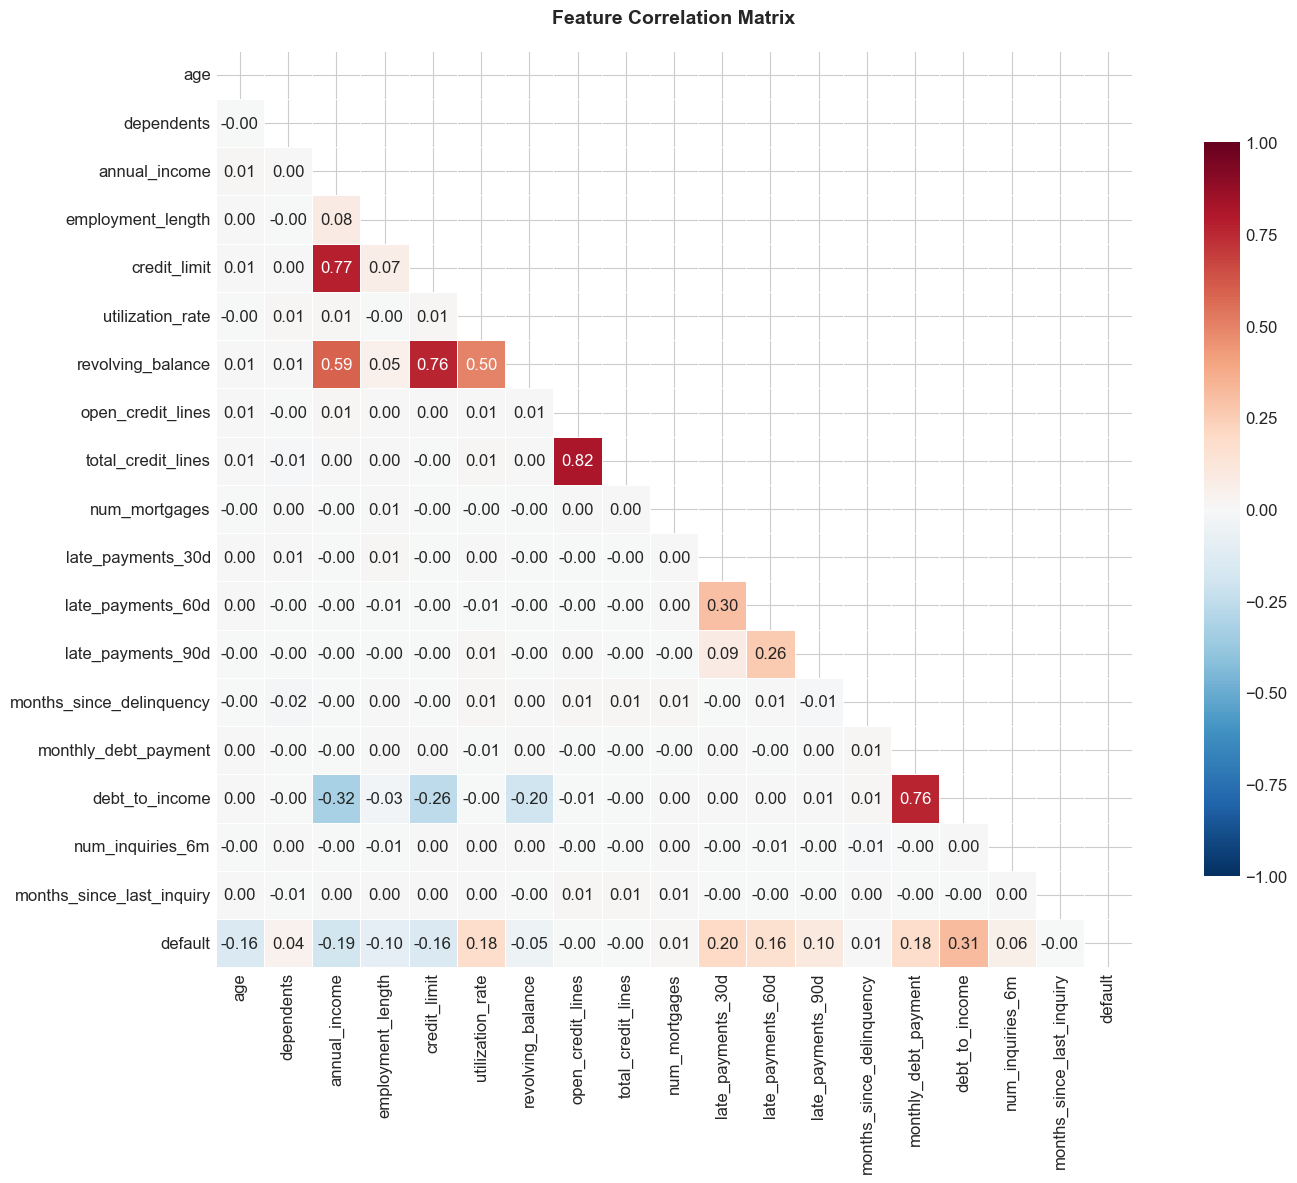

Top Features Correlated with Default:
---------------------------------------------
  debt_to_income                      +0.3128
  late_payments_30d                   +0.1964
  annual_income                       -0.1936
  utilization_rate                    +0.1838
  monthly_debt_payment                +0.1830
  late_payments_60d                   +0.1570
  age                                 -0.1558
  credit_limit                        -0.1553
  late_payments_90d                   +0.0991
  employment_length                   -0.0978


In [8]:
corr = df[numerical_cols + ['default']].corr()

fig, ax = plt.subplots(figsize=(16, 12))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Feature Correlation Matrix', fontweight='bold', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

target_corr = corr['default'].drop('default').abs().sort_values(ascending=False)
print("Top Features Correlated with Default:")
print("-" * 45)
for feat, val in target_corr.head(10).items():
    sign = '+' if corr.loc[feat, 'default'] > 0 else '-'
    print(f"  {feat:35s} {sign}{val:.4f}")

### 4.5 Key EDA Insights

1. **Class imbalance** -- defaults are the minority class. Instead of resampling, the
   notebook keeps the natural distribution and uses a cost-based decision threshold.
2. **Payment history** -- late-payment counts and utilisation are among the strongest
   signals (check the correlation list above).
3. **Income, age, tenure** -- higher values go with lower default rates.
4. **Multicollinearity** -- the 30/60/90-day late-payment counts are correlated with each
   other, which matters for the logistic regression.

---
## 5. Feature Engineering

In [9]:
df_fe = df.copy()

# "Never delinquent" is a meaningful state, not a random gap: encode it as a long gap
df_fe['months_since_delinquency'] = df_fe['months_since_delinquency'].fillna(120)

# Payment-behaviour features
df_fe['total_late_payments'] = (
    df_fe['late_payments_30d'] + df_fe['late_payments_60d'] + df_fe['late_payments_90d']
)
df_fe['severe_delinquency_flag'] = (df_fe['late_payments_90d'] > 0).astype(int)
df_fe['delinquency_severity_ratio'] = np.where(
    df_fe['total_late_payments'] > 0,
    df_fe['late_payments_90d'] / df_fe['total_late_payments'],
    0,
)

# Financial-health ratios
monthly_income = df_fe['annual_income'] / 12
df_fe['payment_to_income'] = (df_fe['monthly_debt_payment'] / monthly_income).clip(0, 10)
df_fe['balance_to_income'] = (df_fe['revolving_balance'] / df_fe['annual_income']).clip(0, 10)
df_fe['credit_limit_to_income'] = (df_fe['credit_limit'] / df_fe['annual_income']).clip(0, 10)

# Account-stability features
df_fe['credit_line_ratio'] = (df_fe['open_credit_lines'] / df_fe['total_credit_lines']).clip(0, 1)
df_fe['available_credit'] = df_fe['credit_limit'] - df_fe['revolving_balance']
df_fe['available_credit_pct'] = (df_fe['available_credit'] / df_fe['credit_limit']).clip(0, 1)

# Inquiry intensity
df_fe['inquiry_intensity'] = np.where(
    df_fe['months_since_last_inquiry'] > 0,
    df_fe['num_inquiries_6m'] / df_fe['months_since_last_inquiry'],
    df_fe['num_inquiries_6m'],
)

new_features = [c for c in df_fe.columns if c not in df.columns]
print(f"Original features: {df.shape[1]}")
print(f"After engineering: {df_fe.shape[1]}  (+{len(new_features)} new)")
print("\nNew features:")
for f in new_features:
    print(f"  - {f}")

Original features: 22
After engineering: 32  (+10 new)

New features:
  - total_late_payments
  - severe_delinquency_flag
  - delinquency_severity_ratio
  - payment_to_income
  - balance_to_income
  - credit_limit_to_income
  - credit_line_ratio
  - available_credit
  - available_credit_pct
  - inquiry_intensity


### 5.2 Information Value (IV)

IV ranks how well each feature separates defaulters from non-defaulters. It is used
here for feature screening and inspection (the models below use the raw numeric
features, not WoE-encoded ones).

| IV Range | Predictive Power |
|----------|-----------------|
| < 0.02 | Not useful |
| 0.02 - 0.1 | Weak |
| 0.1 - 0.3 | Medium |
| 0.3 - 0.5 | Strong |
| > 0.5 | Suspicious (check for leakage) |

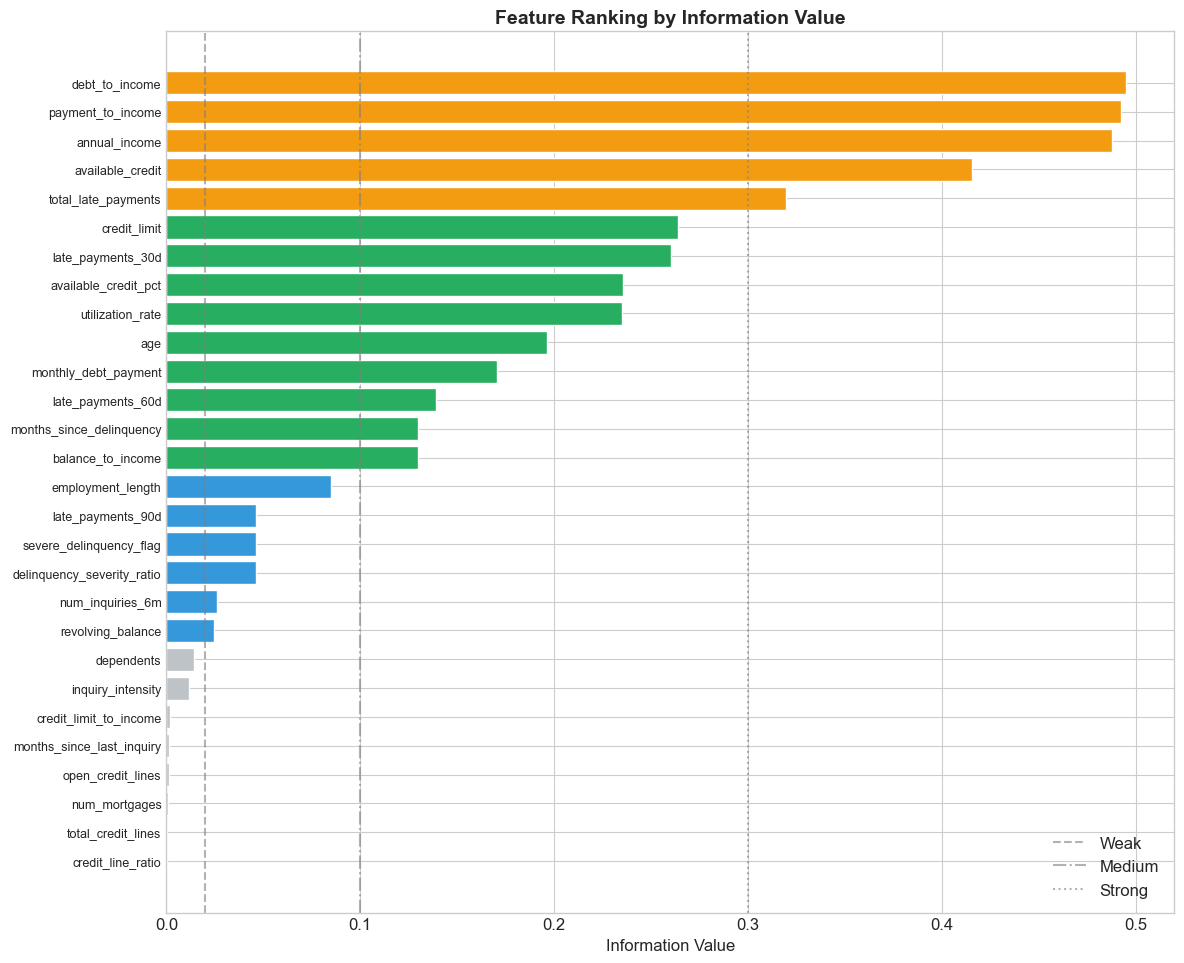


Information Value Summary:
                                  IV       Power
debt_to_income              0.494872      Strong
payment_to_income           0.492220      Strong
annual_income               0.487869      Strong
available_credit            0.415378      Strong
total_late_payments         0.319755      Strong
credit_limit                0.264010      Medium
late_payments_30d           0.260255      Medium
available_credit_pct        0.235249      Medium
utilization_rate            0.235195      Medium
age                         0.196186      Medium
monthly_debt_payment        0.170394      Medium
late_payments_60d           0.139174      Medium
months_since_delinquency    0.129928      Medium
balance_to_income           0.129761      Medium
employment_length           0.085007        Weak
late_payments_90d           0.046254        Weak
severe_delinquency_flag     0.046254        Weak
delinquency_severity_ratio  0.046220        Weak
num_inquiries_6m            0.025861     

In [10]:
def calculate_woe_iv(data, feature, target, bins=10):
    """Calculate WoE table and total IV for a single feature."""
    tmp = data[[feature, target]].dropna().copy()
    if tmp[feature].nunique() <= 10:
        grouped = tmp.groupby(feature)
    else:
        tmp['_bin'] = pd.qcut(tmp[feature], q=bins, duplicates='drop')
        grouped = tmp.groupby('_bin', observed=True)

    stats = grouped[target].agg(['count', 'sum'])
    stats.columns = ['total', 'events']
    stats['non_events'] = stats['total'] - stats['events']
    stats['pct_e'] = (stats['events'] / stats['events'].sum()).replace(0, 0.0001)
    stats['pct_ne'] = (stats['non_events'] / stats['non_events'].sum()).replace(0, 0.0001)
    stats['woe'] = np.log(stats['pct_ne'] / stats['pct_e'])
    stats['iv_bin'] = (stats['pct_ne'] - stats['pct_e']) * stats['woe']
    return stats, stats['iv_bin'].sum()


all_num = [c for c in df_fe.select_dtypes(include=[np.number]).columns if c != 'default']
iv_results = {}
for col in all_num:
    try:
        _, iv = calculate_woe_iv(df_fe, col, 'default')
        iv_results[col] = iv
    except Exception as e:
        print(f"IV skipped for {col}: {e}")

iv_df = (
    pd.DataFrame.from_dict(iv_results, orient='index', columns=['IV'])
    .sort_values('IV', ascending=False)
)
iv_df['Power'] = pd.cut(
    iv_df['IV'],
    bins=[-np.inf, 0.02, 0.1, 0.3, 0.5, np.inf],
    labels=['Not Useful', 'Weak', 'Medium', 'Strong', 'Suspicious'],
)

fig, ax = plt.subplots(figsize=(12, max(8, len(iv_df) * 0.35)))
bar_colors = iv_df['IV'].apply(
    lambda x: COLORS['danger'] if x > 0.5
    else COLORS['warning'] if x > 0.3
    else COLORS['success'] if x > 0.1
    else COLORS['info'] if x > 0.02
    else '#BDC3C7'
)
ax.barh(range(len(iv_df)), iv_df['IV'], color=bar_colors, edgecolor='white')
ax.set_yticks(range(len(iv_df)))
ax.set_yticklabels(iv_df.index, fontsize=9)
ax.set_xlabel('Information Value')
ax.set_title('Feature Ranking by Information Value', fontweight='bold', fontsize=14)
ax.axvline(0.02, color='gray', ls='--', alpha=.6, label='Weak')
ax.axvline(0.1, color='gray', ls='-.', alpha=.6, label='Medium')
ax.axvline(0.3, color='gray', ls=':', alpha=.6, label='Strong')
ax.legend(loc='lower right')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print("\nInformation Value Summary:")
print("=" * 55)
print(iv_df.to_string())

---
## 6. Data Preprocessing

Order matters here: split first, then fit the imputer and scaler on the training set
only, so no test-set information leaks into training.

In [11]:
# 6.1 Build the feature matrix
feature_cols = [c for c in df_fe.select_dtypes(include=[np.number]).columns if c != 'default']

for col in categorical_cols:
    df_fe[col + '_enc'] = LabelEncoder().fit_transform(df_fe[col].astype(str))
    feature_cols.append(col + '_enc')

X = df_fe[feature_cols].copy()
y = df_fe['default'].copy()

print(f"Feature matrix: {X.shape}")
print(f"\nFeatures ({len(feature_cols)}):")
for i, c in enumerate(feature_cols, 1):
    print(f"  {i:2d}. {c}")

Feature matrix: (50000, 31)

Features (31):
   1. age
   2. dependents
   3. annual_income
   4. employment_length
   5. credit_limit
   6. utilization_rate
   7. revolving_balance
   8. open_credit_lines
   9. total_credit_lines
  10. num_mortgages
  11. late_payments_30d
  12. late_payments_60d
  13. late_payments_90d
  14. months_since_delinquency
  15. monthly_debt_payment
  16. debt_to_income
  17. num_inquiries_6m
  18. months_since_last_inquiry
  19. total_late_payments
  20. severe_delinquency_flag
  21. delinquency_severity_ratio
  22. payment_to_income
  23. balance_to_income
  24. credit_limit_to_income
  25. credit_line_ratio
  26. available_credit
  27. available_credit_pct
  28. inquiry_intensity
  29. education_enc
  30. marital_status_enc
  31. home_ownership_enc


In [12]:
# 6.2 Train / test split (before imputing or scaling)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y,
)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print(f"Train: {X_train.shape[0]:,}  |  Test: {X_test.shape[0]:,}")
print(f"Train default rate: {y_train.mean():.2%}")
print(f"Test  default rate: {y_test.mean():.2%}")

Train: 40,000  |  Test: 10,000
Train default rate: 15.35%
Test  default rate: 15.36%


In [13]:
# 6.3 Impute (median, fitted on train only)
print("Missing in train before imputation:")
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])

imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=feature_cols)
X_test = pd.DataFrame(imputer.transform(X_test), columns=feature_cols)

print("\nMissing after imputation:", X_train.isnull().sum().sum() + X_test.isnull().sum().sum())

Missing in train before imputation:
annual_income             1616
employment_length         2351
payment_to_income         1616
balance_to_income         1616
credit_limit_to_income    1616
dtype: int64

Missing after imputation: 0


In [14]:
# 6.4 Scale (fitted on train only)
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=feature_cols)

print("Scaling complete.")
print(f"Train mean ~ 0:  {X_train_s.mean().mean():.6f}")
print(f"Train std  ~ 1:  {X_train_s.std().mean():.6f}")

Scaling complete.
Train mean ~ 0:  0.000000
Train std  ~ 1:  1.000013


---
## 7. Model Development

Four models of increasing complexity, all trained on the same scaled training data.

### 7.1 Logistic Regression (Baseline)

In [15]:
lr = LogisticRegression(C=0.1, max_iter=2000, random_state=RANDOM_STATE)
lr.fit(X_train_s, y_train)

lr_pred = lr.predict_proba(X_test_s)[:, 1]
print(f"Logistic Regression  --  Test AUC: {roc_auc_score(y_test, lr_pred):.4f}")

Logistic Regression  --  Test AUC: 0.8394


### 7.2 Random Forest

In [16]:
rf = RandomForestClassifier(
    n_estimators=300, max_depth=12, min_samples_split=20, min_samples_leaf=10,
    max_features='sqrt', random_state=RANDOM_STATE, n_jobs=-1,
)
rf.fit(X_train_s, y_train)

rf_pred = rf.predict_proba(X_test_s)[:, 1]
print(f"Random Forest  --  Test AUC: {roc_auc_score(y_test, rf_pred):.4f}")

Random Forest  --  Test AUC: 0.8299


### 7.3 XGBoost with Bayesian Hyperparameter Tuning (Optuna)

In [17]:
def xgb_objective(trial):
    params = dict(
        n_estimators=trial.suggest_int('n_estimators', 100, 400),
        max_depth=trial.suggest_int('max_depth', 3, 8),
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        subsample=trial.suggest_float('subsample', 0.6, 1.0),
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.6, 1.0),
        min_child_weight=trial.suggest_int('min_child_weight', 1, 10),
        reg_alpha=trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        reg_lambda=trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0,
    )
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    scores = []
    for tr_idx, va_idx in cv.split(X_train_s, y_train):
        m = XGBClassifier(**params)
        m.fit(X_train_s.iloc[tr_idx], y_train.iloc[tr_idx])
        p = m.predict_proba(X_train_s.iloc[va_idx])[:, 1]
        scores.append(roc_auc_score(y_train.iloc[va_idx], p))
    return np.mean(scores)


print("Running Optuna optimisation for XGBoost (25 trials). This takes a few minutes ...")
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(xgb_objective, n_trials=25)

print(f"\nBest CV AUC: {study.best_value:.4f}")
print(f"Best params: {study.best_params}")

Running Optuna optimisation for XGBoost (25 trials). This takes a few minutes ...

Best CV AUC: 0.8385
Best params: {'n_estimators': 234, 'max_depth': 6, 'learning_rate': 0.030467921491907832, 'subsample': 0.6400829626526331, 'colsample_bytree': 0.8606191144454811, 'min_child_weight': 5, 'reg_alpha': 2.03083335102901e-08, 'reg_lambda': 0.827765732254647}


In [18]:
best_params = {**study.best_params, 'random_state': RANDOM_STATE, 'n_jobs': -1, 'verbosity': 0}
xgb = XGBClassifier(**best_params)
xgb.fit(X_train_s, y_train)

xgb_pred = xgb.predict_proba(X_test_s)[:, 1]
print(f"XGBoost (tuned)  --  Test AUC: {roc_auc_score(y_test, xgb_pred):.4f}")

XGBoost (tuned)  --  Test AUC: 0.8372


### 7.4 LightGBM

In [19]:
lgbm = LGBMClassifier(
    n_estimators=400, max_depth=8, learning_rate=0.05,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, min_child_samples=20,
    reg_alpha=0.1, reg_lambda=0.1,
    random_state=RANDOM_STATE, verbose=-1,
)
lgbm.fit(X_train_s, y_train)

lgbm_pred = lgbm.predict_proba(X_test_s)[:, 1]
print(f"LightGBM  --  Test AUC: {roc_auc_score(y_test, lgbm_pred):.4f}")

LightGBM  --  Test AUC: 0.8324


---
## 8. Model Evaluation and Comparison

Cost-optimal decision threshold: 0.1176


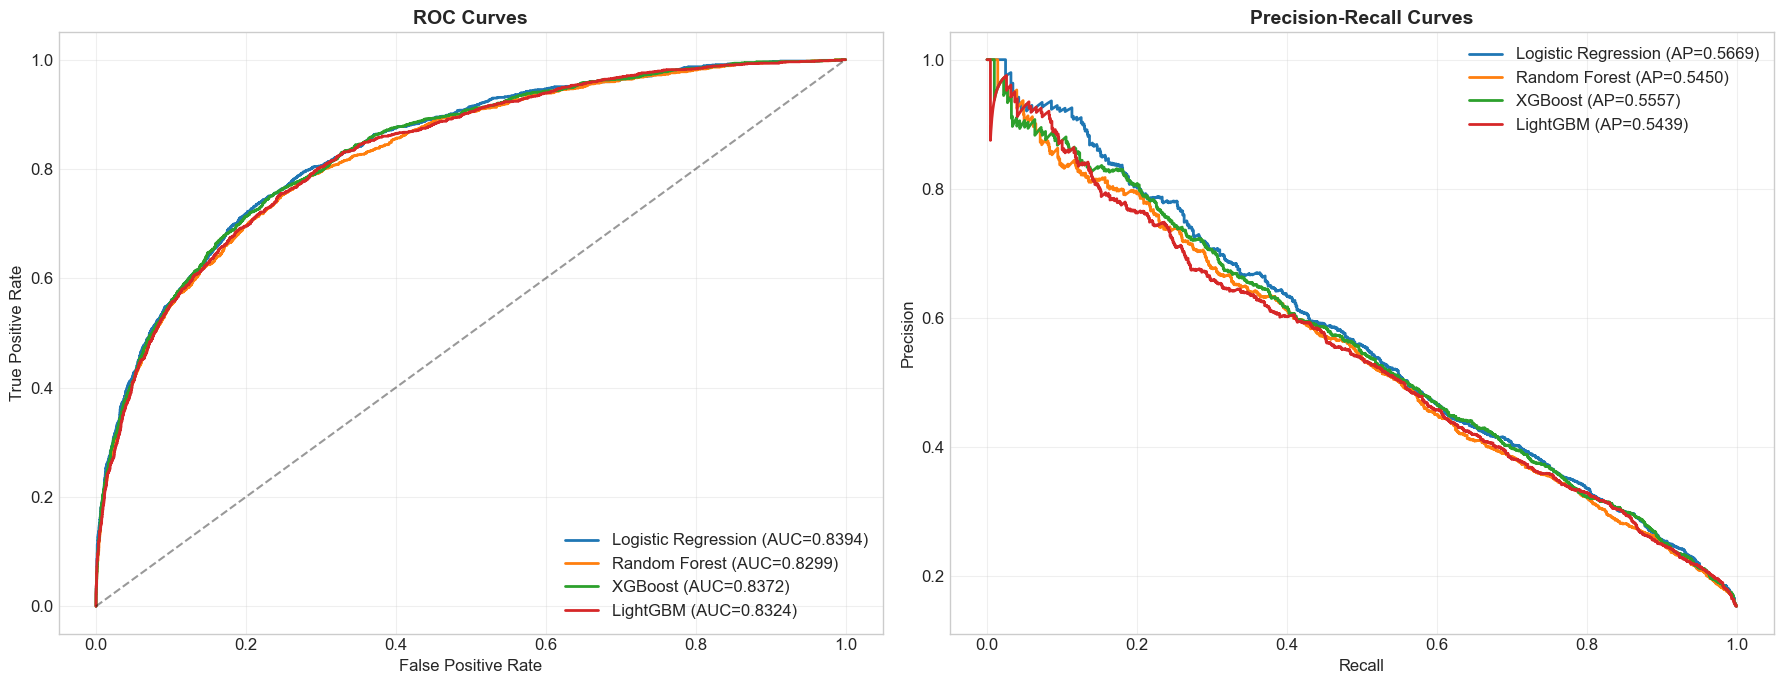

In [20]:
MODELS = {
    'Logistic Regression': lr_pred,
    'Random Forest': rf_pred,
    'XGBoost': xgb_pred,
    'LightGBM': lgbm_pred,
}
MODEL_OBJS = {
    'Logistic Regression': lr,
    'Random Forest': rf,
    'XGBoost': xgb,
    'LightGBM': lgbm,
}

COST_FN = 15_000   # missed default
COST_FP = 2_000    # rejected good applicant
THRESHOLD = COST_FP / (COST_FP + COST_FN)
print(f"Cost-optimal decision threshold: {THRESHOLD:.4f}")

# 8.1 ROC and Precision-Recall curves
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for name, pred in MODELS.items():
    fpr, tpr, _ = roc_curve(y_test, pred)
    axes[0].plot(fpr, tpr, lw=2, label=f'{name} (AUC={roc_auc_score(y_test, pred):.4f})')
    prec, rec, _ = precision_recall_curve(y_test, pred)
    axes[1].plot(rec, prec, lw=2, label=f'{name} (AP={average_precision_score(y_test, pred):.4f})')

axes[0].plot([0, 1], [0, 1], 'k--', alpha=.4)
axes[0].set(xlabel='False Positive Rate', ylabel='True Positive Rate')
axes[0].set_title('ROC Curves', fontweight='bold')
axes[0].legend(loc='lower right')
axes[0].grid(True, alpha=.3)

axes[1].set(xlabel='Recall', ylabel='Precision')
axes[1].set_title('Precision-Recall Curves', fontweight='bold')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=.3)

plt.tight_layout()
plt.show()

In [21]:
# 8.2 Metrics table (classification metrics at the cost-based threshold)
rows = []
for name, pred in MODELS.items():
    yhat = (pred >= THRESHOLD).astype(int)
    rows.append({
        'Model': name,
        'AUC-ROC': roc_auc_score(y_test, pred),
        'Avg Precision': average_precision_score(y_test, pred),
        'Accuracy': accuracy_score(y_test, yhat),
        'Precision': precision_score(y_test, yhat),
        'Recall': recall_score(y_test, yhat),
        'F1': f1_score(y_test, yhat),
        'Log Loss': log_loss(y_test, pred),
    })

results_df = pd.DataFrame(rows).set_index('Model').round(4)
print("=" * 85)
print(f"MODEL COMPARISON  (threshold = {THRESHOLD:.3f})")
print("=" * 85)
print(results_df.to_string())

best_name = results_df['AUC-ROC'].idxmax()
print(f"\nBest model by AUC-ROC: {best_name}")

MODEL COMPARISON  (threshold = 0.118)
                     AUC-ROC  Avg Precision  Accuracy  Precision  Recall      F1  Log Loss
Model                                                                                     
Logistic Regression   0.8394         0.5669    0.7050     0.3198  0.8171  0.4597    0.3142
Random Forest         0.8299         0.5450    0.6695     0.2950  0.8288  0.4351    0.3237
XGBoost               0.8372         0.5557    0.7104     0.3224  0.8034  0.4601    0.3168
LightGBM              0.8324         0.5439    0.7226     0.3315  0.7930  0.4676    0.3221

Best model by AUC-ROC: Logistic Regression


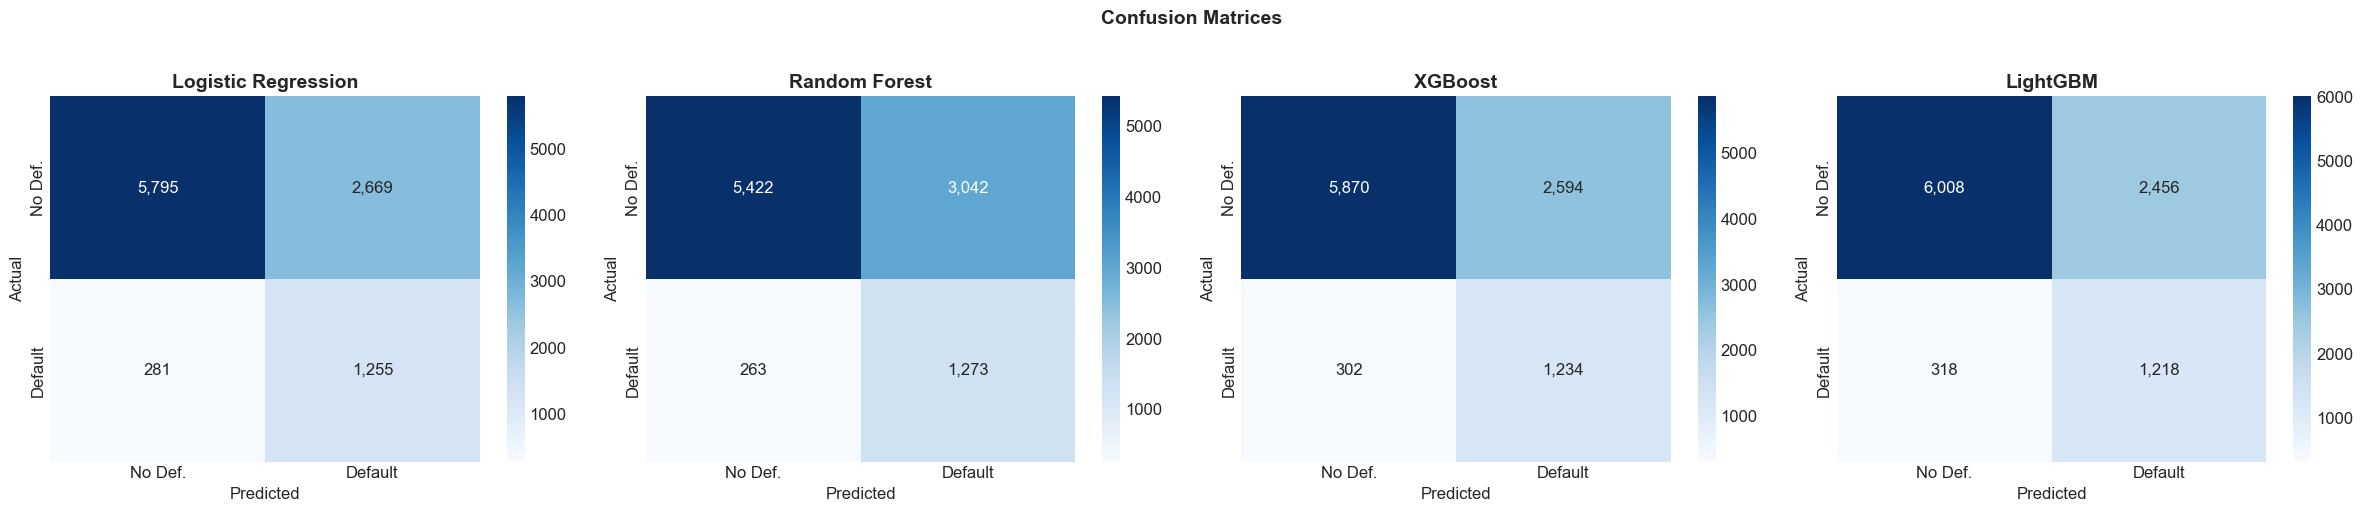

In [22]:
# 8.3 Confusion matrices
fig, axes = plt.subplots(1, 4, figsize=(24, 5))

for i, (name, pred) in enumerate(MODELS.items()):
    cm = confusion_matrix(y_test, (pred >= THRESHOLD).astype(int))
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=axes[i],
                xticklabels=['No Def.', 'Default'],
                yticklabels=['No Def.', 'Default'])
    axes[i].set_title(name, fontweight='bold')
    axes[i].set_ylabel('Actual')
    axes[i].set_xlabel('Predicted')

plt.suptitle('Confusion Matrices', fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [23]:
# 8.4 Business impact (cost-benefit)
print("=" * 65)
print("BUSINESS IMPACT ANALYSIS")
print("=" * 65)

baseline = y_test.sum() * COST_FN   # cost if everyone is approved
print(f"Baseline cost (approve everyone): ${baseline:,.0f}")

for name, pred in MODELS.items():
    tn, fp, fn, tp = confusion_matrix(y_test, (pred >= THRESHOLD).astype(int)).ravel()
    total_cost = fn * COST_FN + fp * COST_FP
    print(f"\n{name}:")
    print(f"  Defaults caught:      {tp:,} / {tp + fn:,} ({tp / (tp + fn) * 100:.1f}%)")
    print(f"  Good applicants lost: {fp:,} / {tn + fp:,} ({fp / (tn + fp) * 100:.1f}%)")
    print(f"  Total cost:           ${total_cost:,.0f}")
    print(f"  Net savings:          ${baseline - total_cost:,.0f}")

BUSINESS IMPACT ANALYSIS
Baseline cost (approve everyone): $23,040,000

Logistic Regression:
  Defaults caught:      1,255 / 1,536 (81.7%)
  Good applicants lost: 2,669 / 8,464 (31.5%)
  Total cost:           $9,553,000
  Net savings:          $13,487,000

Random Forest:
  Defaults caught:      1,273 / 1,536 (82.9%)
  Good applicants lost: 3,042 / 8,464 (35.9%)
  Total cost:           $10,029,000
  Net savings:          $13,011,000

XGBoost:
  Defaults caught:      1,234 / 1,536 (80.3%)
  Good applicants lost: 2,594 / 8,464 (30.6%)
  Total cost:           $9,718,000
  Net savings:          $13,322,000

LightGBM:
  Defaults caught:      1,218 / 1,536 (79.3%)
  Good applicants lost: 2,456 / 8,464 (29.0%)
  Total cost:           $9,682,000
  Net savings:          $13,358,000


---
## 9. Model Explainability (SHAP)

SHAP gives global feature importance and per-applicant explanations, which supports
reason codes for adverse-action notices (ECOA / FCRA).

In [24]:
best_model = MODEL_OBJS[best_name]
print(f"Explaining: {best_name}")

X_explain = X_test_s.sample(n=min(2000, len(X_test_s)), random_state=RANDOM_STATE)
y_explain = y_test.loc[X_explain.index]

if best_name == 'Logistic Regression':
    explainer = shap.LinearExplainer(best_model, X_train_s)
else:
    explainer = shap.TreeExplainer(best_model)

shap_values = explainer.shap_values(X_explain)

# Different SHAP / model versions return a list, a 3-D array, or a 2-D array.
# Reduce to a (samples, features) array for the positive (default) class.
if isinstance(shap_values, list):
    shap_values = shap_values[1]
elif np.ndim(shap_values) == 3:
    shap_values = shap_values[:, :, 1]

base_val = float(np.ravel(explainer.expected_value)[-1])
print(f"SHAP values shape: {shap_values.shape}")

Background dataset has 40000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=40000 when initializing the masker.


Explaining: Logistic Regression
SHAP values shape: (2000, 31)


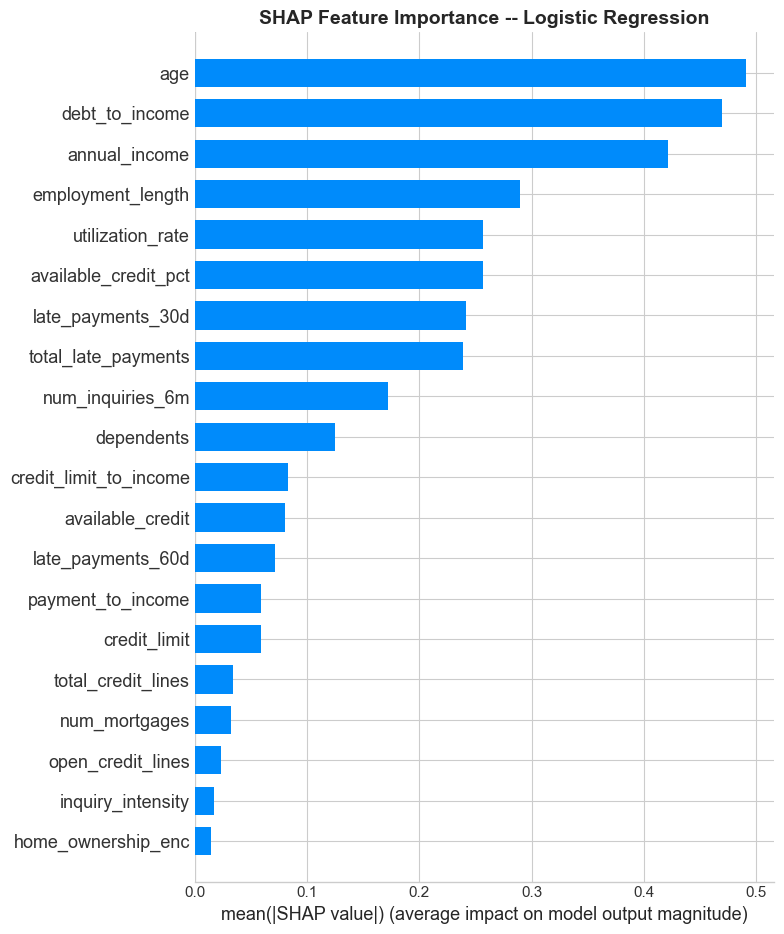

In [25]:
# 9.1 Global importance
plt.figure(figsize=(12, 10))
shap.summary_plot(shap_values, X_explain, plot_type='bar', show=False, max_display=20)
plt.title(f'SHAP Feature Importance -- {best_name}', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

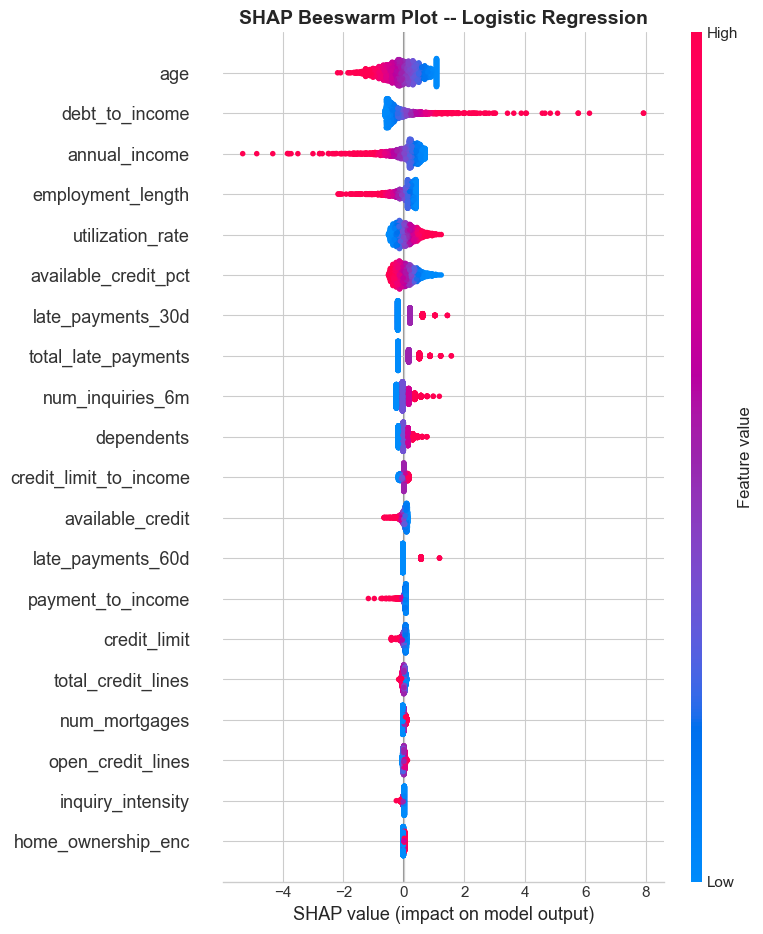

In [26]:
# 9.2 Beeswarm (direction of impact)
plt.figure(figsize=(12, 10))
shap.summary_plot(shap_values, X_explain, show=False, max_display=20)
plt.title(f'SHAP Beeswarm Plot -- {best_name}', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

High-risk applicant:  P(default) = 0.9992  |  Actual = 1
Low-risk applicant:   P(default) = 0.0001  |  Actual = 0


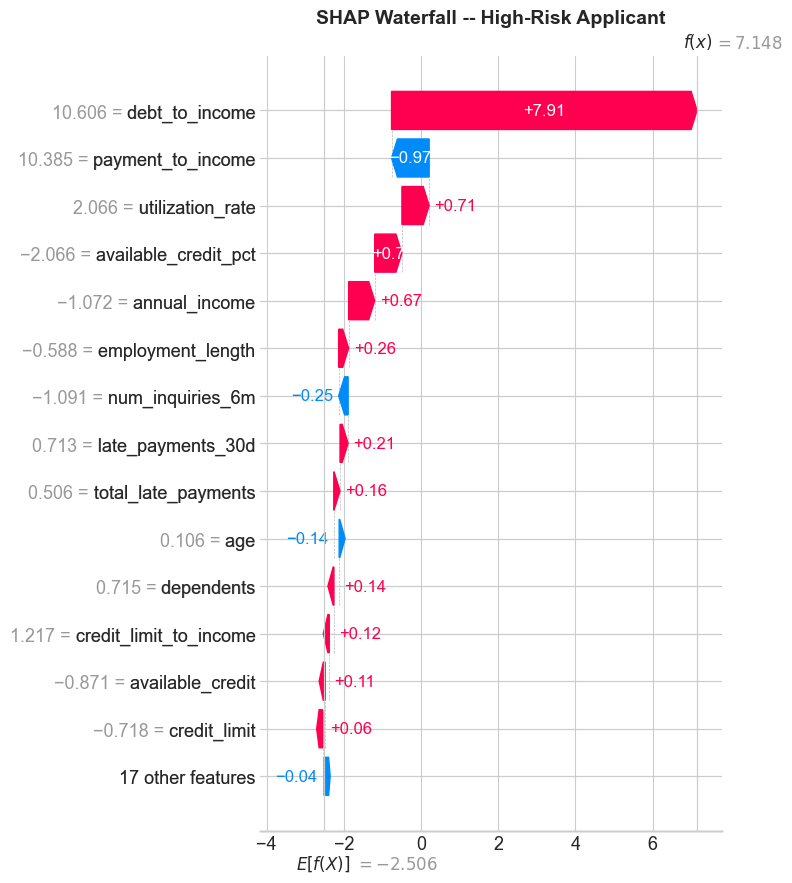

In [27]:
# 9.3 Individual explanation: highest-risk applicant in the sample
best_pred_sample = best_model.predict_proba(X_explain)[:, 1]
hi_idx = int(np.argmax(best_pred_sample))
lo_idx = int(np.argmin(best_pred_sample))

print(f"High-risk applicant:  P(default) = {best_pred_sample[hi_idx]:.4f}  |  Actual = {y_explain.iloc[hi_idx]}")
print(f"Low-risk applicant:   P(default) = {best_pred_sample[lo_idx]:.4f}  |  Actual = {y_explain.iloc[lo_idx]}")

sv_hi = shap.Explanation(
    values=shap_values[hi_idx],
    base_values=base_val,
    data=X_explain.iloc[hi_idx].values,
    feature_names=X_explain.columns.tolist(),
)
shap.plots.waterfall(sv_hi, max_display=15, show=False)
plt.title('SHAP Waterfall -- High-Risk Applicant', fontweight='bold')
plt.tight_layout()
plt.show()

---
## 10. Credit Scorecard

The model's default probability is mapped to a points-based score:

$$\text{Score} = \text{Offset} + \text{Factor} \times \ln\left(\frac{1-p}{p}\right)$$

- Base score of 600 at good:bad odds of 50:1 (about 2 % default rate)
- Points to Double the Odds (PDO) = 20
- Scores are clipped to the familiar 300-850 range

In [28]:
BASE_SCORE = 600
TARGET_ODDS = 50
PDO = 20

FACTOR = PDO / np.log(2)
OFFSET = BASE_SCORE - FACTOR * np.log(TARGET_ODDS)

print("Scorecard parameters:")
print(f"  Base Score  : {BASE_SCORE}")
print(f"  Target Odds : {TARGET_ODDS}:1")
print(f"  PDO         : {PDO}")
print(f"  Factor      : {FACTOR:.4f}")
print(f"  Offset      : {OFFSET:.4f}")


def prob_to_score(prob):
    """Map default probability to a 300-850 credit score."""
    prob = np.clip(np.asarray(prob, dtype=float), 1e-4, 1 - 1e-4)
    score = OFFSET + FACTOR * np.log((1 - prob) / prob)
    return np.clip(np.round(score), 300, 850).astype(int)


test_scores = prob_to_score(MODELS[best_name])

print("\nTest-set score statistics:")
print(f"  Min    : {test_scores.min()}")
print(f"  Max    : {test_scores.max()}")
print(f"  Mean   : {test_scores.mean():.0f}")
print(f"  Median : {int(np.median(test_scores))}")

Scorecard parameters:
  Base Score  : 600
  Target Odds : 50:1
  PDO         : 20
  Factor      : 28.8539
  Offset      : 487.1229

Test-set score statistics:
  Min    : 300
  Max    : 753
  Mean   : 557
  Median : 558


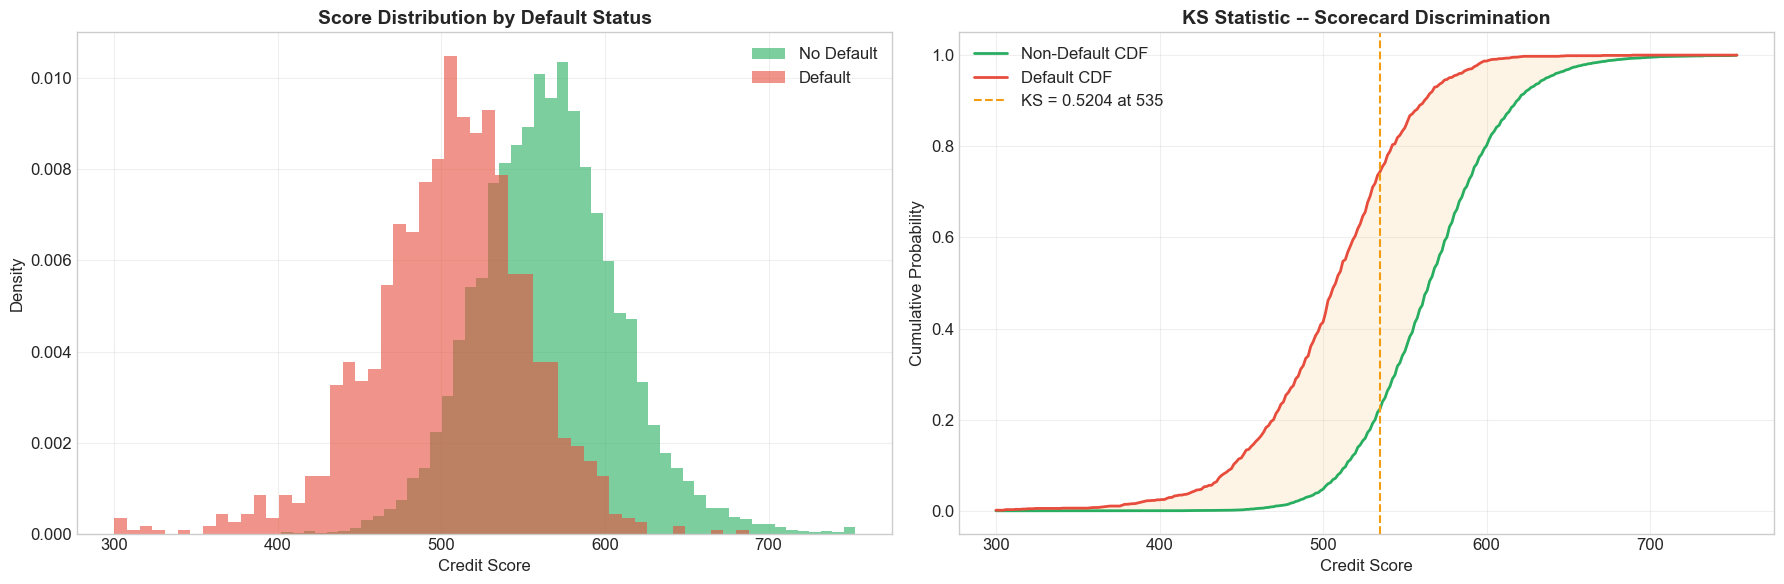

KS Statistic:     0.5204  (at score 535)
Gini Coefficient: 0.6788


In [29]:
# 10.1 Score distribution and KS statistic
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for label, color, name in [(0, COLORS['success'], 'No Default'),
                           (1, COLORS['danger'], 'Default')]:
    m = y_test.values == label
    axes[0].hist(test_scores[m], bins=50, alpha=.6, color=color, label=name, density=True)
axes[0].set(xlabel='Credit Score', ylabel='Density')
axes[0].set_title('Score Distribution by Default Status', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=.3)

sr = np.linspace(test_scores.min(), test_scores.max(), 300)
cdf_d = np.array([np.mean(test_scores[y_test.values == 1] <= s) for s in sr])
cdf_nd = np.array([np.mean(test_scores[y_test.values == 0] <= s) for s in sr])
ks = np.max(np.abs(cdf_nd - cdf_d))
ks_at = sr[np.argmax(np.abs(cdf_nd - cdf_d))]

axes[1].plot(sr, cdf_nd, color=COLORS['success'], lw=2, label='Non-Default CDF')
axes[1].plot(sr, cdf_d, color=COLORS['danger'], lw=2, label='Default CDF')
axes[1].axvline(ks_at, color=COLORS['warning'], ls='--', label=f'KS = {ks:.4f} at {ks_at:.0f}')
axes[1].fill_between(sr, cdf_nd, cdf_d, alpha=.1, color=COLORS['warning'])
axes[1].set(xlabel='Credit Score', ylabel='Cumulative Probability')
axes[1].set_title('KS Statistic -- Scorecard Discrimination', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=.3)

plt.tight_layout()
plt.show()

# A higher score means lower risk, so rank defaults by the negative score
auc_best = roc_auc_score(y_test, -test_scores)
gini = 2 * auc_best - 1
print(f"KS Statistic:     {ks:.4f}  (at score {ks_at:.0f})")
print(f"Gini Coefficient: {gini:.4f}")

In [30]:
# 10.2 Risk-band segmentation
BAND_EDGES = [0, 500, 550, 600, 650, 700, 851]
BAND_LABELS = ['Very High Risk', 'High Risk', 'Medium-High', 'Medium', 'Low Risk', 'Very Low Risk']
BAND_DECISION = {
    'Very High Risk': 'Decline',
    'High Risk': 'Decline',
    'Medium-High': 'Manual Review',
    'Medium': 'Conditional Approve',
    'Low Risk': 'Approve',
    'Very Low Risk': 'Approve',
}

bands = pd.cut(test_scores, bins=BAND_EDGES, labels=BAND_LABELS, right=False)

band_df = pd.DataFrame({'Score': test_scores, 'Default': y_test.values, 'Band': bands})
summary = band_df.groupby('Band', observed=True).agg(
    Count=('Default', 'count'),
    Defaults=('Default', 'sum'),
    Default_Rate=('Default', 'mean'),
    Avg_Score=('Score', 'mean'),
).round(4)
summary['Pct_Total'] = (summary['Count'] / summary['Count'].sum() * 100).round(2)
summary['Decision'] = [BAND_DECISION[b] for b in summary.index]

print("=" * 95)
print("CREDIT SCORECARD -- RISK-BAND ANALYSIS")
print("=" * 95)
print(summary.to_string())

CREDIT SCORECARD -- RISK-BAND ANALYSIS
                Count  Defaults  Default_Rate  Avg_Score  Pct_Total             Decision
Band                                                                                    
Very High Risk   1038       636        0.6127   469.2755      10.38              Decline
High Risk        3213       655        0.2039   527.7890      32.13              Decline
Medium-High      4051       225        0.0555   573.0047      40.51        Manual Review
Medium           1430        18        0.0126   617.6769      14.30  Conditional Approve
Low Risk          227         2        0.0088   666.9559       2.27              Approve
Very Low Risk      41         0        0.0000   722.4878       0.41              Approve


In [31]:
# 10.3 Check against the success criteria from Section 2
best_pred = MODELS[best_name]
recall_best = recall_score(y_test, (best_pred >= THRESHOLD).astype(int))

checks = [
    ('ROC-AUC > 0.80', roc_auc_score(y_test, best_pred), 0.80),
    ('Recall (default) > 0.70', recall_best, 0.70),
    ('KS > 0.40', ks, 0.40),
    ('Gini > 0.60', gini, 0.60),
]
print(f"Success criteria for {best_name}:")
for name, value, target in checks:
    print(f"  {name:28s} {value:.4f}   {'PASS' if value > target else 'FAIL'}")

Success criteria for Logistic Regression:
  ROC-AUC > 0.80               0.8394   PASS
  Recall (default) > 0.70      0.8171   PASS
  KS > 0.40                    0.5204   PASS
  Gini > 0.60                  0.6788   PASS


---
## 11. Model Monitoring (PSI)

The Population Stability Index measures how far a live population has drifted from a
reference (training) population.

| PSI | Interpretation |
|-----|---------------|
| < 0.10 | No significant shift |
| 0.10 - 0.25 | Moderate shift, investigate |
| > 0.25 | Significant shift, retrain |

In [32]:
def psi(expected, actual, bins=10):
    """Population Stability Index, with open-ended outer bins."""
    edges = np.unique(np.percentile(expected, np.linspace(0, 100, bins + 1)))
    if len(edges) < 3:
        return 0.0   # constant or binary-like feature: nothing to bin
    edges[0], edges[-1] = -np.inf, np.inf
    e_counts = np.histogram(expected, bins=edges)[0]
    a_counts = np.histogram(actual, bins=edges)[0]
    e_pct = np.where(e_counts == 0, 1e-4, e_counts / e_counts.sum())
    a_pct = np.where(a_counts == 0, 1e-4, a_counts / a_counts.sum())
    return float(np.sum((a_pct - e_pct) * np.log(a_pct / e_pct)))


def psi_label(v):
    return 'OK' if v < .10 else 'INVESTIGATE' if v < .25 else 'RETRAIN'


# Simulated monitoring: first half of the test set = baseline, second half = "production"
half = len(X_test) // 2
baseline_scores = test_scores[:half]
production_scores = test_scores[half:]

rng_drift = np.random.RandomState(99)
drifted_scores = (production_scores + rng_drift.normal(30, 15, len(production_scores))).astype(int)

psi_stable = psi(baseline_scores, production_scores)
psi_drifted = psi(baseline_scores, drifted_scores)

print("Score-Level PSI:")
print(f"  Stable scenario:  {psi_stable:.4f}  [{psi_label(psi_stable)}]")
print(f"  Drifted scenario: {psi_drifted:.4f}  [{psi_label(psi_drifted)}]")

Score-Level PSI:
  Stable scenario:  0.0022  [OK]
  Drifted scenario: 0.3808  [RETRAIN]


FEATURE-LEVEL DRIFT MONITORING
                  Feature      PSI Status
        revolving_balance 0.006963     OK
months_since_last_inquiry 0.006691     OK
   credit_limit_to_income 0.003913     OK
        open_credit_lines 0.003504     OK
             credit_limit 0.003468     OK
            annual_income 0.003174     OK
     available_credit_pct 0.002817     OK
         utilization_rate 0.002806     OK
        inquiry_intensity 0.002666     OK
        credit_line_ratio 0.002613     OK
        employment_length 0.002603     OK
       total_credit_lines 0.002394     OK
           debt_to_income 0.001827     OK
     monthly_debt_payment 0.001690     OK
        payment_to_income 0.001540     OK


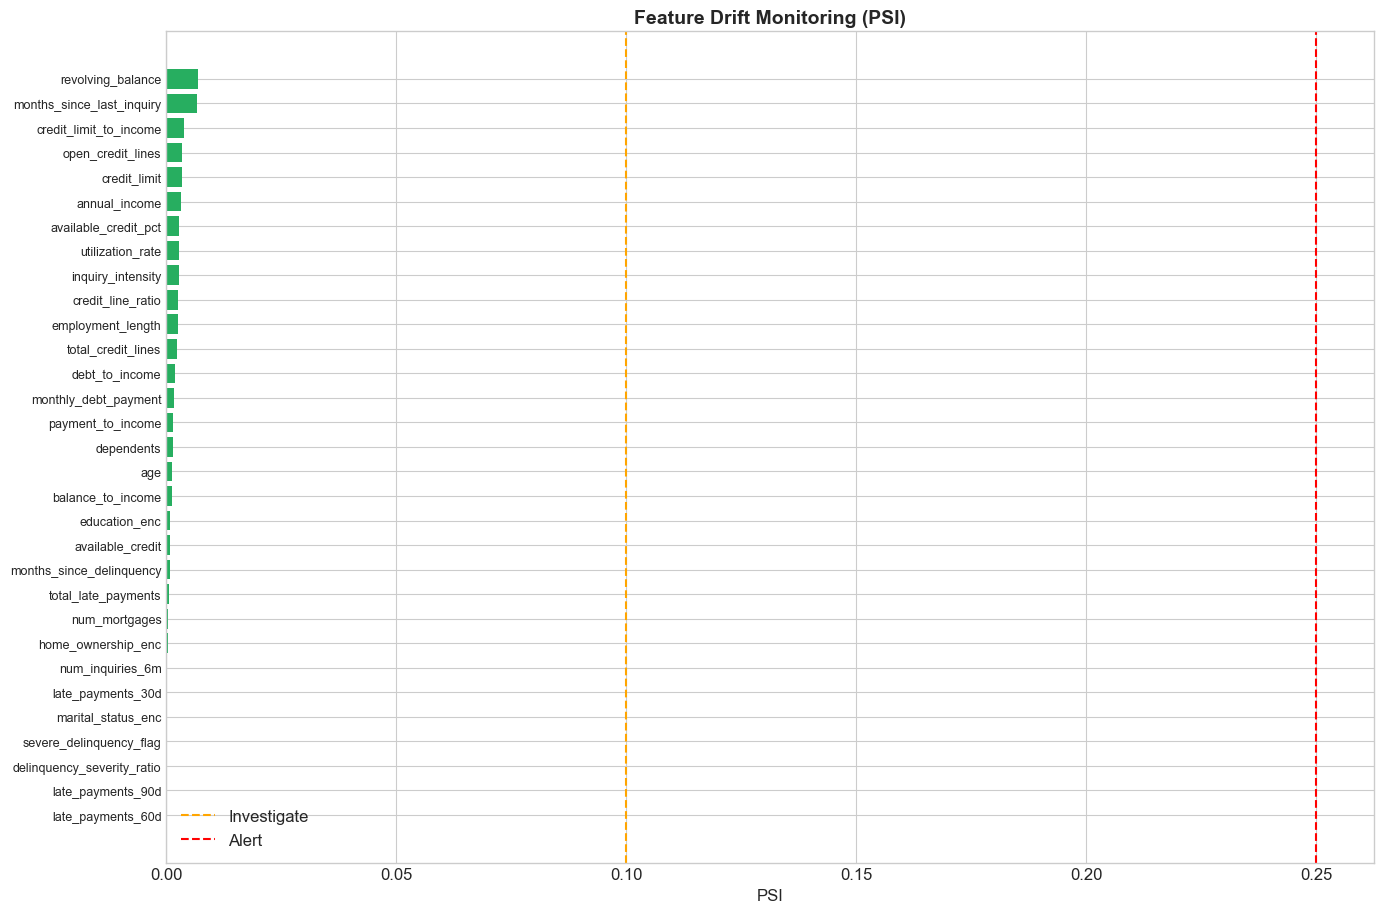

In [33]:
# Feature-level drift
X_base = X_test_s.iloc[:half]
X_prod = X_test_s.iloc[half:]

drift_df = pd.DataFrame(
    [{'Feature': c, 'PSI': psi(X_base[c].values, X_prod[c].values)} for c in X_test_s.columns]
).sort_values('PSI', ascending=False)
drift_df['Status'] = drift_df['PSI'].map(psi_label)

print("=" * 60)
print("FEATURE-LEVEL DRIFT MONITORING")
print("=" * 60)
print(drift_df.head(15).to_string(index=False))

fig, ax = plt.subplots(figsize=(14, max(6, len(drift_df) * 0.3)))
dc = drift_df['PSI'].map(lambda v: COLORS['danger'] if v > .25
                         else COLORS['warning'] if v > .10 else COLORS['success'])
ax.barh(range(len(drift_df)), drift_df['PSI'].values, color=dc.values)
ax.set_yticks(range(len(drift_df)))
ax.set_yticklabels(drift_df['Feature'].values, fontsize=9)
ax.axvline(.10, color='orange', ls='--', label='Investigate')
ax.axvline(.25, color='red', ls='--', label='Alert')
ax.set_xlabel('PSI')
ax.set_title('Feature Drift Monitoring (PSI)', fontweight='bold')
ax.legend()
ax.invert_yaxis()
plt.tight_layout()
plt.show()

---
## 12. Interactive Risk Assessment Dashboard

A Gradio dashboard for scoring one applicant. Inputs are grouped into four sections. The result
panel shows the score, the decision, a ruler built from the scorecard bands in Section 10.2, the
default probability and the main risk drivers. Features that are not collected in the form
(education, marital status, home ownership, dependents, etc.) are set to the training median.

In [34]:
import inspect
import gradio as gr

train_median = X_train.median()

# ---------------------------------------------------------------- prediction
def assess_risk(age, income, emp_len, credit_limit, util_rate, rev_bal,
                open_lines, total_lines, mortgages, late30, late60, late90,
                monthly_debt, inquiries, months_since_inq):
    """Build the feature vector exactly as in training, predict, return an HTML report."""
    try:
        age, emp_len, util_rate, rev_bal = [(v or 0) for v in (age, emp_len, util_rate, rev_bal)]
        open_lines, total_lines, mortgages = [(v or 0) for v in (open_lines, total_lines, mortgages)]
        late30, late60, late90 = [(v or 0) for v in (late30, late60, late90)]
        monthly_debt, inquiries, months_since_inq = [(v or 0) for v in (monthly_debt, inquiries, months_since_inq)]

        income = max(float(income or 0), 1.0)
        credit_limit = max(float(credit_limit or 0), 1.0)
        total_lines = max(total_lines, open_lines, 1)

        total_late = late30 + late60 + late90
        dti = min((monthly_debt * 12) / income, 5)
        avail = credit_limit - rev_bal

        row = pd.DataFrame([train_median.values], columns=feature_cols)
        values = {
            'age': age,
            'annual_income': income,
            'employment_length': emp_len,
            'credit_limit': credit_limit,
            'utilization_rate': util_rate,
            'revolving_balance': rev_bal,
            'open_credit_lines': open_lines,
            'total_credit_lines': total_lines,
            'num_mortgages': mortgages,
            'late_payments_30d': late30,
            'late_payments_60d': late60,
            'late_payments_90d': late90,
            'months_since_delinquency': 120 if total_late == 0 else row.loc[0, 'months_since_delinquency'],
            'monthly_debt_payment': monthly_debt,
            'debt_to_income': dti,
            'num_inquiries_6m': inquiries,
            'months_since_last_inquiry': months_since_inq,
            'total_late_payments': total_late,
            'severe_delinquency_flag': int(late90 > 0),
            'delinquency_severity_ratio': late90 / total_late if total_late else 0,
            'payment_to_income': min(monthly_debt / (income / 12), 10),
            'balance_to_income': min(rev_bal / income, 10),
            'credit_limit_to_income': min(credit_limit / income, 10),
            'credit_line_ratio': min(open_lines / total_lines, 1),
            'available_credit': avail,
            'available_credit_pct': min(max(avail / credit_limit, 0), 1),
            'inquiry_intensity': inquiries / months_since_inq if months_since_inq > 0 else inquiries,
        }
        for k, v in values.items():
            row[k] = v

        row_s = pd.DataFrame(scaler.transform(row), columns=feature_cols)
        prob = float(best_model.predict_proba(row_s)[0][1])
        score = int(prob_to_score(prob))
        band = BAND_LABELS[np.searchsorted(BAND_EDGES, score, side='right') - 1]
        decision = BAND_DECISION[band]
    except Exception as e:
        return ('<div class="res"><div class="err">We couldn\'t score this applicant. Check the values and try again.'
                f'<details><summary>Show error details</summary>{type(e).__name__}: {e}</details></div></div>')

    # ---- presentation
    tone = {'Approve': '#2E7D5B', 'Conditional Approve': '#5E8A2E',
            'Manual Review': '#A86A12', 'Decline': '#B83A33'}[decision]

    seg_colors = ['#C9534B', '#D9825B', '#D9A441', '#B8B45A', '#7FAE7A', '#4F9A6E']
    segs = ''
    for i, lab in enumerate(BAND_LABELS):
        lo, hi = max(BAND_EDGES[i], 300), min(BAND_EDGES[i + 1], 850)
        on = 1 if lab == band else 0.3
        segs += f'<span class="seg" style="flex:{hi - lo};background:{seg_colors[i]};opacity:{on}"></span>'
    ticks = ''.join(
        f'<span class="tick" style="left:{(t - 300) / 5.5:.2f}%">{t}</span>'
        for t in (300, 500, 550, 600, 650, 700, 850))
    pos = (score - 300) / 5.5

    def factor(name, value, level):
        word, color = {0: ('Good', '#2E7D5B'), 1: ('Watch', '#A86A12'), 2: ('High', '#B83A33')}[level]
        return (f'<div class="f-row"><span class="f-name">{name}</span><span class="f-val">{value}</span>'
                f'<span class="f-state" style="color:{color}"><i style="background:{color}"></i>{word}</span></div>')

    factors = ''.join([
        factor('Credit utilisation', f'{util_rate:.0%}', 2 if util_rate > 0.5 else 1 if util_rate > 0.3 else 0),
        factor('Debt-to-income', f'{dti:.2f}', 2 if dti > 0.4 else 1 if dti > 0.3 else 0),
        factor('Late payments', f'{total_late}', 2 if late90 > 0 else 1 if total_late > 0 else 0),
        factor('Inquiries, 6 months', f'{inquiries}', 2 if inquiries > 5 else 1 if inquiries > 3 else 0),
        factor('Credit lines', f'{total_lines}', 1 if total_lines < 4 else 0),
    ])

    return f"""
    <div class="res">
      <div class="r-label">Credit score</div>
      <div class="r-head">
        <span class="r-score">{score}</span>
        <span class="r-decision" style="color:{tone}">{decision}</span>
      </div>
      <div class="ruler-wrap">
        <div class="ruler">{segs}<span class="mk" style="left:{pos:.2f}%"></span></div>
        <div class="ticks">{ticks}</div>
      </div>
      <div class="kv"><span>Default probability</span><b>{prob:.2%}</b></div>
      <div class="kv"><span>Risk band</span><b>{band}</b></div>
      <div class="r-sub">Main drivers</div>
      {factors}
    </div>"""


# ---------------------------------------------------------------- styling
CSS = """
:root {--ink:#1A2230; --muted:#5B6675; --line:rgba(26,34,48,.10); --accent:#2F4B7C;}
.gradio-container {max-width: 1200px !important; margin: 0 auto !important; padding: 24px 24px 48px !important;
                   font-family: 'IBM Plex Sans', system-ui, sans-serif !important; color: var(--ink);}
footer {visibility: hidden;}
.gradio-container, .gradio-container * {font-variant-numeric: tabular-nums;}

.hdr h1 {font-size: 24px; line-height: 1.2; font-weight: 600; letter-spacing: -0.01em; margin: 0;}
.hdr p {font-size: 14px; line-height: 1.5; color: var(--muted); margin: 8px 0 0;}

.panel {background: #fff !important; border: 1px solid var(--line) !important; border-radius: 12px !important;
        padding: 8px 24px 24px !important; gap: 16px !important; box-shadow: none !important;}
.panel .block, .panel .form {border: none !important; box-shadow: none !important;
                             background: transparent !important; padding: 0 !important;}
.sec {border-top: 1px solid var(--line); padding-top: 24px; margin-top: 16px;}
.sec.first {border-top: none; margin-top: 0;}
.sec b {display: block; font-size: 16px; line-height: 1.25; font-weight: 600;}
.sec span {display: block; font-size: 14px; line-height: 1.5; color: var(--muted); margin-top: 4px;}

.panel span[data-testid="block-info"], .panel label > span {font-size: 14px !important; font-weight: 500 !important; color: var(--muted) !important;}
.panel input[type=number], .panel input[type=text] {font-size: 16px !important; min-height: 44px; border-radius: 8px !important;}
button {min-height: 44px; font-size: 14px !important; font-weight: 500 !important; border-radius: 8px !important;}

#side {position: sticky; top: 24px; align-self: flex-start; gap: 16px;}
.res {background: #fff; border: 1px solid var(--line); border-radius: 12px; padding: 24px;}
.r-label {font-size: 14px; color: var(--muted);}
.r-head {display: flex; align-items: baseline; justify-content: space-between; gap: 16px; margin: 4px 0 24px;}
.r-score {font-size: 40px; line-height: 1.1; font-weight: 600; letter-spacing: -0.02em;}
.r-decision {font-size: 16px; font-weight: 600;}
.ruler-wrap {margin-bottom: 32px;}
.ruler {position: relative; display: flex; gap: 2px; height: 8px;}
.seg {border-radius: 2px;}
.seg:first-child {border-radius: 4px 2px 2px 4px;}
.seg:last-child {border-radius: 2px 4px 4px 2px;}
.mk {position: absolute; top: -6px; width: 2px; height: 20px; margin-left: -1px; background: var(--ink); border-radius: 1px;}
.ticks {position: relative; height: 16px; margin-top: 12px;}
.tick {position: absolute; transform: translateX(-50%); font-size: 12px; line-height: 1.4; color: var(--muted);}
.tick:first-child {transform: none;}
.tick:last-child {transform: translateX(-100%);}
.kv {display: flex; justify-content: space-between; padding: 12px 0; border-top: 1px solid var(--line); font-size: 14px;}
.kv span {color: var(--muted);}
.kv b {font-weight: 600;}
.r-sub {font-size: 14px; font-weight: 600; margin: 24px 0 4px;}
.f-row {display: grid; grid-template-columns: 1fr auto 72px; gap: 12px; align-items: center;
        padding: 12px 0; border-top: 1px solid var(--line); font-size: 14px;}
.f-name {color: var(--muted);}
.f-val {font-weight: 500;}
.f-state {display: inline-flex; align-items: center; gap: 8px; justify-content: flex-end; font-weight: 500;}
.f-state i {width: 8px; height: 8px; border-radius: 50%; display: inline-block;}
.err {font-size: 14px; line-height: 1.5; color: #B83A33;}
.err details {margin-top: 8px; color: var(--muted); font-size: 12px;}

@media (max-width: 767px) {
  .gradio-container {padding: 16px !important;}
  #side {position: static;}
  .panel {padding: 8px 16px 16px !important;}
}
"""

LIGHT = dict(
    body_background_fill='#EEF0F2',
    background_fill_primary='#ffffff',
    background_fill_secondary='#F6F7F8',
    block_background_fill='#ffffff',
    block_border_color='rgba(26,34,48,.10)',
    block_label_text_color='#5B6675',
    body_text_color='#1A2230',
    input_background_fill='#F6F7F8',
    input_border_color='rgba(26,34,48,.14)',
    input_border_color_focus='#2F4B7C',
    slider_color='#2F4B7C',
    button_primary_background_fill='#2F4B7C',
    button_primary_background_fill_hover='#263E69',
    button_primary_text_color='#ffffff',
    button_secondary_background_fill='#ffffff',
    button_secondary_background_fill_hover='#F1F3F5',
    button_secondary_border_color='rgba(26,34,48,.14)',
    button_secondary_text_color='#1A2230',
)
theme = gr.themes.Base(
    primary_hue='blue', neutral_hue='slate',
    font=[gr.themes.GoogleFont('IBM Plex Sans'), 'system-ui', 'sans-serif'],
    radius_size='md',
).set(**LIGHT, **{k + '_dark': v for k, v in LIGHT.items()})

# keep light mode even if the OS is in dark mode
JS = "() => { document.body.classList.remove('dark'); document.documentElement.classList.remove('dark'); }"

# Gradio 6 takes theme/css/js in launch(); Gradio 5 takes them in Blocks()
ui = dict(theme=theme, css=CSS, js=JS)
if 'theme' in inspect.signature(gr.Blocks.launch).parameters:
    blocks_kw, launch_kw = {}, ui
else:
    blocks_kw, launch_kw = ui, {}

# ---------------------------------------------------------------- layout
PRESETS = {
    'Prime profile':    [45, 110000, 15, 40000, 0.12, 4800, 6, 10, 1, 0, 0, 0, 900, 0, 24],
    'Average profile':  [35, 60000, 5, 15000, 0.30, 4500, 5, 8, 1, 0, 0, 0, 800, 1, 6],
    'Stressed profile': [27, 32000, 1, 8000, 0.85, 6800, 9, 12, 0, 3, 2, 1, 1400, 6, 1],
}


def section(title, hint, first=False):
    cls = 'sec first' if first else 'sec'
    return gr.HTML(f'<div class="{cls}"><b>{title}</b><span>{hint}</span></div>')


with gr.Blocks(title='Credit risk scoring', **blocks_kw) as demo:
    gr.HTML('<div class="hdr"><h1>Credit risk scoring</h1>'
            '<p>Estimate the score, default probability and decision for one applicant.</p></div>')

    with gr.Row(equal_height=False):
        with gr.Column(scale=3, elem_classes='panel'):
            section('Applicant', 'Who is applying and for how long they have worked.', first=True)
            with gr.Row():
                age = gr.Slider(18, 85, value=35, step=1, label='Age')
                emp_len = gr.Slider(0, 40, value=5, step=1, label='Employment length (years)')
            income = gr.Number(value=60000, label='Annual income ($)')

            section('Credit profile', 'Limits, balances and the accounts already open.')
            with gr.Row():
                credit_limit = gr.Number(value=15000, label='Credit limit ($)')
                rev_bal = gr.Number(value=4500, label='Revolving balance ($)')
            util_rate = gr.Slider(0, 1, value=0.30, step=0.01, label='Utilisation rate')
            with gr.Row():
                open_lines = gr.Slider(1, 30, value=5, step=1, label='Open credit lines')
                total_lines = gr.Slider(1, 50, value=8, step=1, label='Total credit lines')
            mortgages = gr.Slider(0, 5, value=1, step=1, label='Mortgages')

            section('Payment history', 'Missed payments by how late they were.')
            with gr.Row():
                late30 = gr.Slider(0, 10, value=0, step=1, label='30 days late')
                late60 = gr.Slider(0, 8, value=0, step=1, label='60 days late')
                late90 = gr.Slider(0, 5, value=0, step=1, label='90 days late')

            section('Debt and inquiries', 'Monthly obligations and recent applications for credit.')
            monthly_debt = gr.Number(value=800, label='Monthly debt payment ($)')
            with gr.Row():
                inquiries = gr.Slider(0, 15, value=1, step=1, label='Credit inquiries (6 months)')
                months_inq = gr.Slider(0, 60, value=6, step=1, label='Months since last inquiry')

        with gr.Column(scale=2, elem_id='side'):
            out = gr.HTML()
            btn = gr.Button('Calculate score', variant='primary')
            sample = gr.Dropdown(list(PRESETS), value='Average profile', label='Sample applicant')
            reset = gr.Button('Reset form')

    inputs = [age, income, emp_len, credit_limit, util_rate, rev_bal, open_lines, total_lines,
              mortgages, late30, late60, late90, monthly_debt, inquiries, months_inq]

    btn.click(assess_risk, inputs, out)
    sample.change(lambda n: PRESETS[n], sample, inputs).then(assess_risk, inputs, out)
    reset.click(lambda: PRESETS['Average profile'] + ['Average profile'], None, inputs + [sample]
                ).then(assess_risk, inputs, out)
    demo.load(assess_risk, inputs, out)

try:
    demo.close()          # stop any server left over from a previous run
except Exception:
    pass
demo.launch(**launch_kw)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


---
## 13. Conclusion

### Summary
- Four models were trained and compared on the same preprocessed data, with the
  imputer and scaler fitted on the training set only.
- The decision threshold comes from the cost ratio (about 0.118), not the default 0.5,
  and no resampling is used, so the predicted probabilities stay calibrated for the scorecard.
- The scorecard maps probabilities to a 300-850 score; Section 10.3 checks the
  AUC, recall, KS and Gini targets from Section 2 on the held-out test set.
- SHAP provides global and per-applicant explanations that can feed adverse-action reason codes.

### Recommendations

| # | Area | Detail |
|---|------|--------|
| 1 | Deployment | Wrap the best model in a REST API (FastAPI) for loan-origination systems. |
| 2 | Pricing | Price by score band: lower rates for 650+, higher margins or secured products below 600. |
| 3 | Monitoring | Run PSI on scores and features regularly; investigate above 0.10, retrain above 0.25. |
| 4 | Compliance | Use top SHAP contributors as reason codes; add a fairness audit before real use. |
| 5 | Refresh | Retrain on a schedule and when PSI alerts fire. |

### Limitations
- The data is synthetic, so absolute metrics are optimistic and not comparable to real
  bureau data. The pipeline, not the numbers, is the deliverable.
- Random splits are used; real credit models should be validated out-of-time.

### Future Work
- Benchmark on a real dataset (for example Give Me Some Credit or Home Credit)
- WoE-binned logistic regression as a regulatory-style scorecard
- Probability calibration and champion-challenger testing
- Experiment tracking with MLflow and fairness-aware modelling